# I. Objective 

This analysis aims to understand the key factors influencing employee attrition and career growth within IBM. By examining attributes such as job role, performance rating, years at the company, work-life balance, and employee satisfaction, the group can identify patterns that contribute to voluntary and involuntary departures. In addition, the study will help recognize high-potential employees suitable for promotion by leveraging data on job involvement, training opportunities, and post-career progression. Through this approach, the group seeks to enhance employee retention strategies and optimize internal talent management. 

# II. Problem Statement

High employee turnover and ineffective talent management at IBM lead to increased costs and lost productivity. This analysis seeks to:  
1. Identify factors driving attrition (e.g., job role, satisfaction, work-life balance).  
2. Spot high-potential employees for promotion based on performance, training, and career growth.  
3. Improve retention strategies to reduce turnover and enhance employee satisfaction.  

By addressing these issues, IBM can reduce costs, retain top talent, and optimize workforce performance.

# III. Background

Employee attrition and talent management are critical issues in the corporate world, as high turnover rates can disrupt operations, increase recruitment costs, and reduce morale. To address these challenges, organizations like IBM can leverage data-driven insights to understand why employees leave and how to identify and retain top talent, ultimately improving workforce stability and performance. The dataset used for this analysis is the **IBM HR Analytics Employee Attrition & Performance Dataset**, available on Kaggle, which contains anonymized employee data focusing on factors related to attrition, performance, and career growth. This data was likely collected through IBM's internal HR systems, including employee surveys, performance reviews, and HR records, and it includes both quantitative metrics (e.g., age, salary, years at the company) and qualitative metrics (e.g., job satisfaction, work-life balance) to provide a comprehensive view of employee dynamics.

# IV. Data Source

The data provider is IBM, and it contains anonymized employee records focusing on factors related to attrition, performance, and career growth. The data was likely gathered through IBM's internal HR systems, including employee surveys, performance reviews, and HR records, and is provided in a structured tabular format (e.g., CSV or Excel). It includes both quantitative metrics (e.g., age, salary, years at the company) and qualitative metrics (e.g., job satisfaction, work-life balance), offering a comprehensive view of employee dynamics.

While the dataset does not explicitly specify the time period it covers, it appears to represent a snapshot of IBM's workforce at a specific point in time, likely spanning multiple years of employee tenure and performance data

# V. Data Description

## Data Structure

### Initial Structure
- **Total Columns**: 35
- **Main Categories**:
  - **Employee Demographics**: Age, Gender, Marital Status, Education, Education Field
  - **Job & Work Details**: Job Role, Department, Job Level, Job Involvement, Job Satisfaction, Work-Life Balance, Overtime, Standard Hours
  - **Compensation & Benefits**: Hourly Rate, Daily Rate, Monthly Income, Stock Options, Salary Hike
  - **Employment History & Tenure**: Years at Company, Years in Current Role, Last Promotion, Years with Manager, Total Working Years, Companies Worked
  - **Employee Satisfaction & Performance**: Performance Rating, Relationship Satisfaction, Environment Satisfaction, Training Times
  - **Attrition & Travel**: Attrition, Business Travel, Distance from Home
  - **Miscellaneous**: Employee Number, Employee Count, Over18

### Data Types
- **Integer (int)**: 14 columns
- **Categorical (object)**: 11 columns
- **Ordinal (int)**: 10 columns

## Transformations Applied

### 1. Dropped Columns
- EmployeeNumber
- HourlyRate & DailyRate
- EmployeeCount, Over18, StandardHours

### 2. Handling Categorical Data
- **Label Encoding (Binary Categories → 0/1)**:
  - Gender
  - Overtime
  - Attrition
- **Ordinal Encoding (Ordered Categories → Numeric Values)**:
  - **BusinessTravel**:
    - Non-Travel → 0
    - Travel_Rarely → 1
    - Travel_Frequently → 2

### 3. Feature Engineering
- **Promotion Stagnation** = `YearsSinceLastPromotion / YearsAtCompany`
- **Role Stagnation** = `YearsInCurrentRole / YearsAtCompany`
- **Manager Tenure Impact** = `YearsWithCurrManager / YearsAtCompany`
- **Income to Hike Ratio** = `MonthlyIncome / PercentageSalaryHike`

## Key Variables

#### Selected Features for Modeling
After preprocessing, we retained a refined set of features crucial for predicting attrition, promotion potential, and retention strategies. The selection process involved feature importance analysis using **mutual information** and **causal impact**.

#### **Models and Retained Features per Objective**

**Objective 1: Identify Factors Driving Attrition**
- **Reasoning:** Focused on understanding why employees leave by analyzing key influencing factors.
- **Retained Features (30 total):**  
  - **Work-related**: Job Role, Department, Job Level, Job Satisfaction, Work-Life Balance, Overtime  
  - **Compensation**: Monthly Income, Stock Options, Salary Hike  
  - **Tenure & Career**: Years at Company, Years in Current Role, Years Since Last Promotion, Years with Current Manager, Total Working Years, Companies Worked  
  - **Satisfaction & Performance**: Performance Rating, Relationship Satisfaction, Environment Satisfaction, Training Times  
  - **Attrition & Travel**: Business Travel, Distance from Home  
- **Processing:** Standardized numerical features and handled **class imbalance** using **SMOTE**.

**Objective 2: Identify High-Potential Employees for Promotion**
- **Reasoning:** Aimed to predict employees most likely to be promoted based on performance, training, and career growth.
- **Retained Features (10 total):**  
  - **Career Growth**: Years Since Last Promotion, Job Level, Training Times Last Year  
  - **Performance & Satisfaction**: Performance Rating, Job Satisfaction, Work-Life Balance  
  - **New Feature**: **High_Potential** (derived based on promotions and performance trends)  
- **Processing:** Applied **One-Hot and Label Encoding** for categorical features.

**Objective 3: Improve Retention Strategies**
- **Reasoning:** Designed to assess the impact of interventions like **Overtime** on attrition to guide HR policies.
- **Retained Features (20 total):**  
  - **Attrition Definition**: Encoded **Attrition** as **binary (Yes = 1, No = 0)**  
  - **Treatment Variable**: **OverTime (Yes = 1, No = 0)** for causal impact analysis  
  - **Work Environment**: Job Satisfaction, Environment Satisfaction, Work-Life Balance  
  - **Compensation**: Monthly Income, Salary Hike  
  - **Career Progression**: Job Level, Training Times, Years Since Last Promotion  
- **Processing:** Cleaned the dataset by **dropping redundant columns** and using **One-Hot Encoding** for categorical data. Selected the **top 20 most important features** using **Mutual Information Classification**.

### **Why These Models Were Retained?**
The selected models align with the business goals and offer the best balance of interpretability, accuracy, and applicability:
1. **Neural Network** – Captures complex relationships in attrition and promotion predictions but requires tuning to avoid overfitting.
2. **XGBoost** – Excels in structured data, handles class imbalance well, and is efficient for feature importance ranking.
3. **Uplift Model** – Critical for **causal analysis**, helping HR teams **target retention interventions effectively**.


## Python Libraries

In [5]:
!pip install lightgbm
!pip install scikit-uplift
!pip install catboost

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, mutual_info_classif, f_classif
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils import class_weight
from sklearn.utils.class_weight import compute_class_weight
from sklift.models import TwoModels
from sklift.metrics import qini_curve, qini_auc_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import regularizers
import xgboost as xgb
from scikeras.wrappers import KerasClassifier
import optuna
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import random
import shap
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.model_selection import(
    cross_val_score, 
    cross_validate, 
    cross_val_predict, 
    learning_curve, 
    GridSearchCV, 
    KFold
)
from sklearn.metrics import roc_auc_score
warnings.simplefilter("ignore")

In [6]:
df = pd.read_csv('IBM-HR-Employee-Attrition.csv')

In [7]:
df.duplicated().sum()

binary_categorical_columns = ['Gender', 'OverTime', 'Attrition']

label_encoder = LabelEncoder()

for col in binary_categorical_columns:
    df[col] = label_encoder.fit_transform(df[col])

business_travel_mapping = {
    'Non-Travel': 0,
    'Travel_Rarely': 1,
    'Travel_Frequently': 2
}

df['BusinessTravel'] = df['BusinessTravel'].map(business_travel_mapping)

numerical_columns = [
    'Age', 'DistanceFromHome', 'MonthlyIncome', 'PercentSalaryHike', 
    'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 
    'YearsWithCurrManager', 'TotalWorkingYears', 'NumCompaniesWorked', 
    'TrainingTimesLastYear'
]

df = pd.get_dummies(df, columns=['Department', 'EducationField', 'JobRole', 'MaritalStatus'], drop_first=True)
df['Over18'] = df['Over18'].map({'Y': 1, 'N': 0})

#scaler = StandardScaler()
#df_scaled = scaler.fit_transform(df)
#df = pd.DataFrame(df_scaled, columns=df.columns)



### Engineered Features

In [8]:
df['PromotionStagnation'] = df['YearsSinceLastPromotion'] / df['YearsAtCompany']
df['RoleStagnation'] = df['YearsInCurrentRole'] / df['YearsAtCompany']
df['ManagerTenureImpact'] = df['YearsWithCurrManager'] / df['YearsAtCompany']
df['IncomeToHikeRatio'] = df['MonthlyIncome'] / df['PercentSalaryHike']

df.replace([float('inf'), -float('inf')], 0, inplace=True)
df.fillna(0, inplace=True)

In [9]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,...,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,PromotionStagnation,RoleStagnation,ManagerTenureImpact,IncomeToHikeRatio
0,41,1,1,1102,1,2,1,1,2,0,...,False,False,True,False,False,True,0.000,0.666667,0.833333,544.818182
1,49,0,2,279,8,1,1,2,3,1,...,False,True,False,False,True,False,0.100,0.700000,0.700000,223.043478
2,37,1,1,1373,2,2,1,4,4,1,...,False,False,False,False,False,True,0.000,0.000000,0.000000,139.333333
3,33,0,2,1392,3,4,1,5,4,0,...,False,True,False,False,True,False,0.375,0.875000,0.000000,264.454545
4,27,0,1,591,2,1,1,7,1,1,...,False,False,False,False,True,False,1.000,1.000000,1.000000,289.000000


In [11]:
df.describe(include='all')

,Age,Attrition,BusinessTravel,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,...,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,PromotionStagnation,RoleStagnation,ManagerTenureImpact,IncomeToHikeRatio
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,...,1470,1470,1470,1470,1470,1470,1470.000000,1470.000000,1470.000000,1470.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2,2,2,2,2,2,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,False,False,False,False,False,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1390,1178,1144,1387,797,1000,NaN,NaN,NaN,NaN
mean,36.923810,0.161224,1.086395,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,0.600000,...,NaN,NaN,NaN,NaN,NaN,NaN,0.290232,0.578220,0.558626,452.815716
std,9.135373,0.367863,0.532170,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,0.490065,...,NaN,NaN,NaN,NaN,NaN,NaN,0.340521,0.331966,0.334732,354.697792
min,18.000000,0.000000,0.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,47.818182
25%,30.000000,0.000000,1.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.352500,0.333333,200.816558
50%,36.000000,0.000000,1.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,0.166667,0.666667,0.666667,341.360390
75%,43.000000,0.000000,1.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,0.500000,0.833333,0.800000,563.627828


In [13]:
df.isnull().sum()

Age                                  0
Attrition                            0
BusinessTravel                       0
DailyRate                            0
DistanceFromHome                     0
Education                            0
EmployeeCount                        0
EmployeeNumber                       0
EnvironmentSatisfaction              0
Gender                               0
HourlyRate                           0
JobInvolvement                       0
JobLevel                             0
JobSatisfaction                      0
MonthlyIncome                        0
MonthlyRate                          0
NumCompaniesWorked                   0
Over18                               0
OverTime                             0
PercentSalaryHike                    0
PerformanceRating                    0
RelationshipSatisfaction             0
StandardHours                        0
StockOptionLevel                     0
TotalWorkingYears                    0
TrainingTimesLastYear    

### Univariate EDA

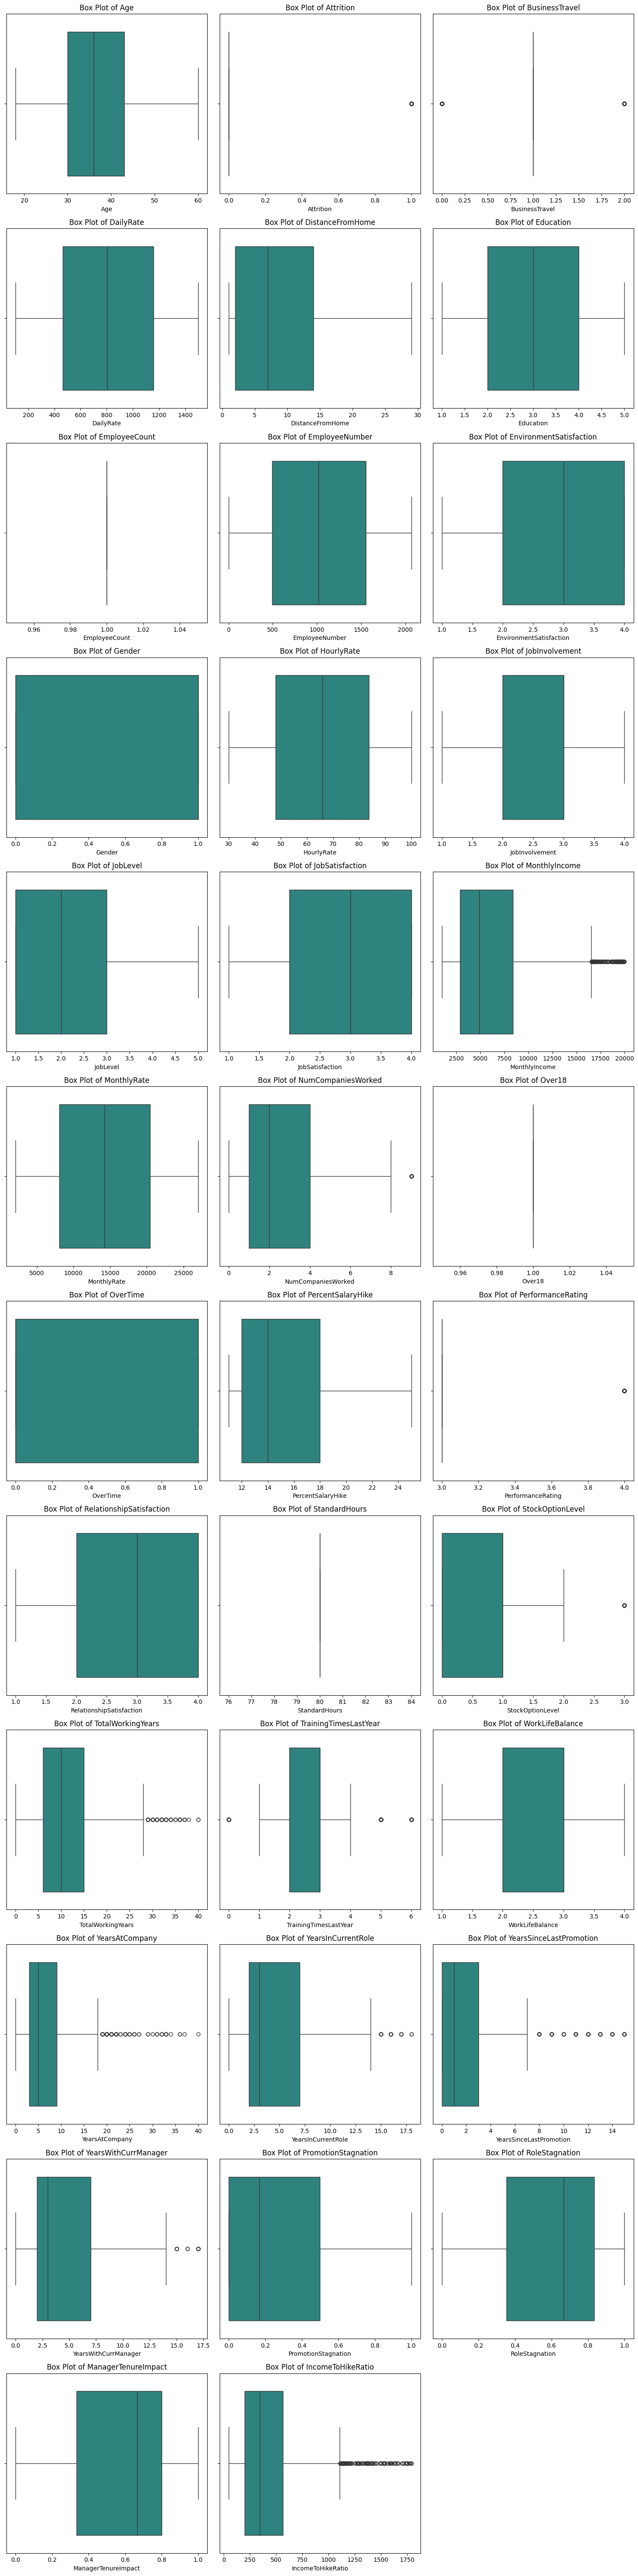

In [15]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

num_cols = len(numerical_columns)
fig, axes = plt.subplots(nrows=(num_cols // 3) + 1, ncols=min(3, num_cols), figsize=(15, 5 * ((num_cols // 3) + 1)))
axes = axes.flatten()

for i, col in enumerate(numerical_columns):
    sns.boxplot(data=df, x=col, palette='viridis', ax=axes[i])
    axes[i].set_title(f"Box Plot of {col}")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Bivariate EDA

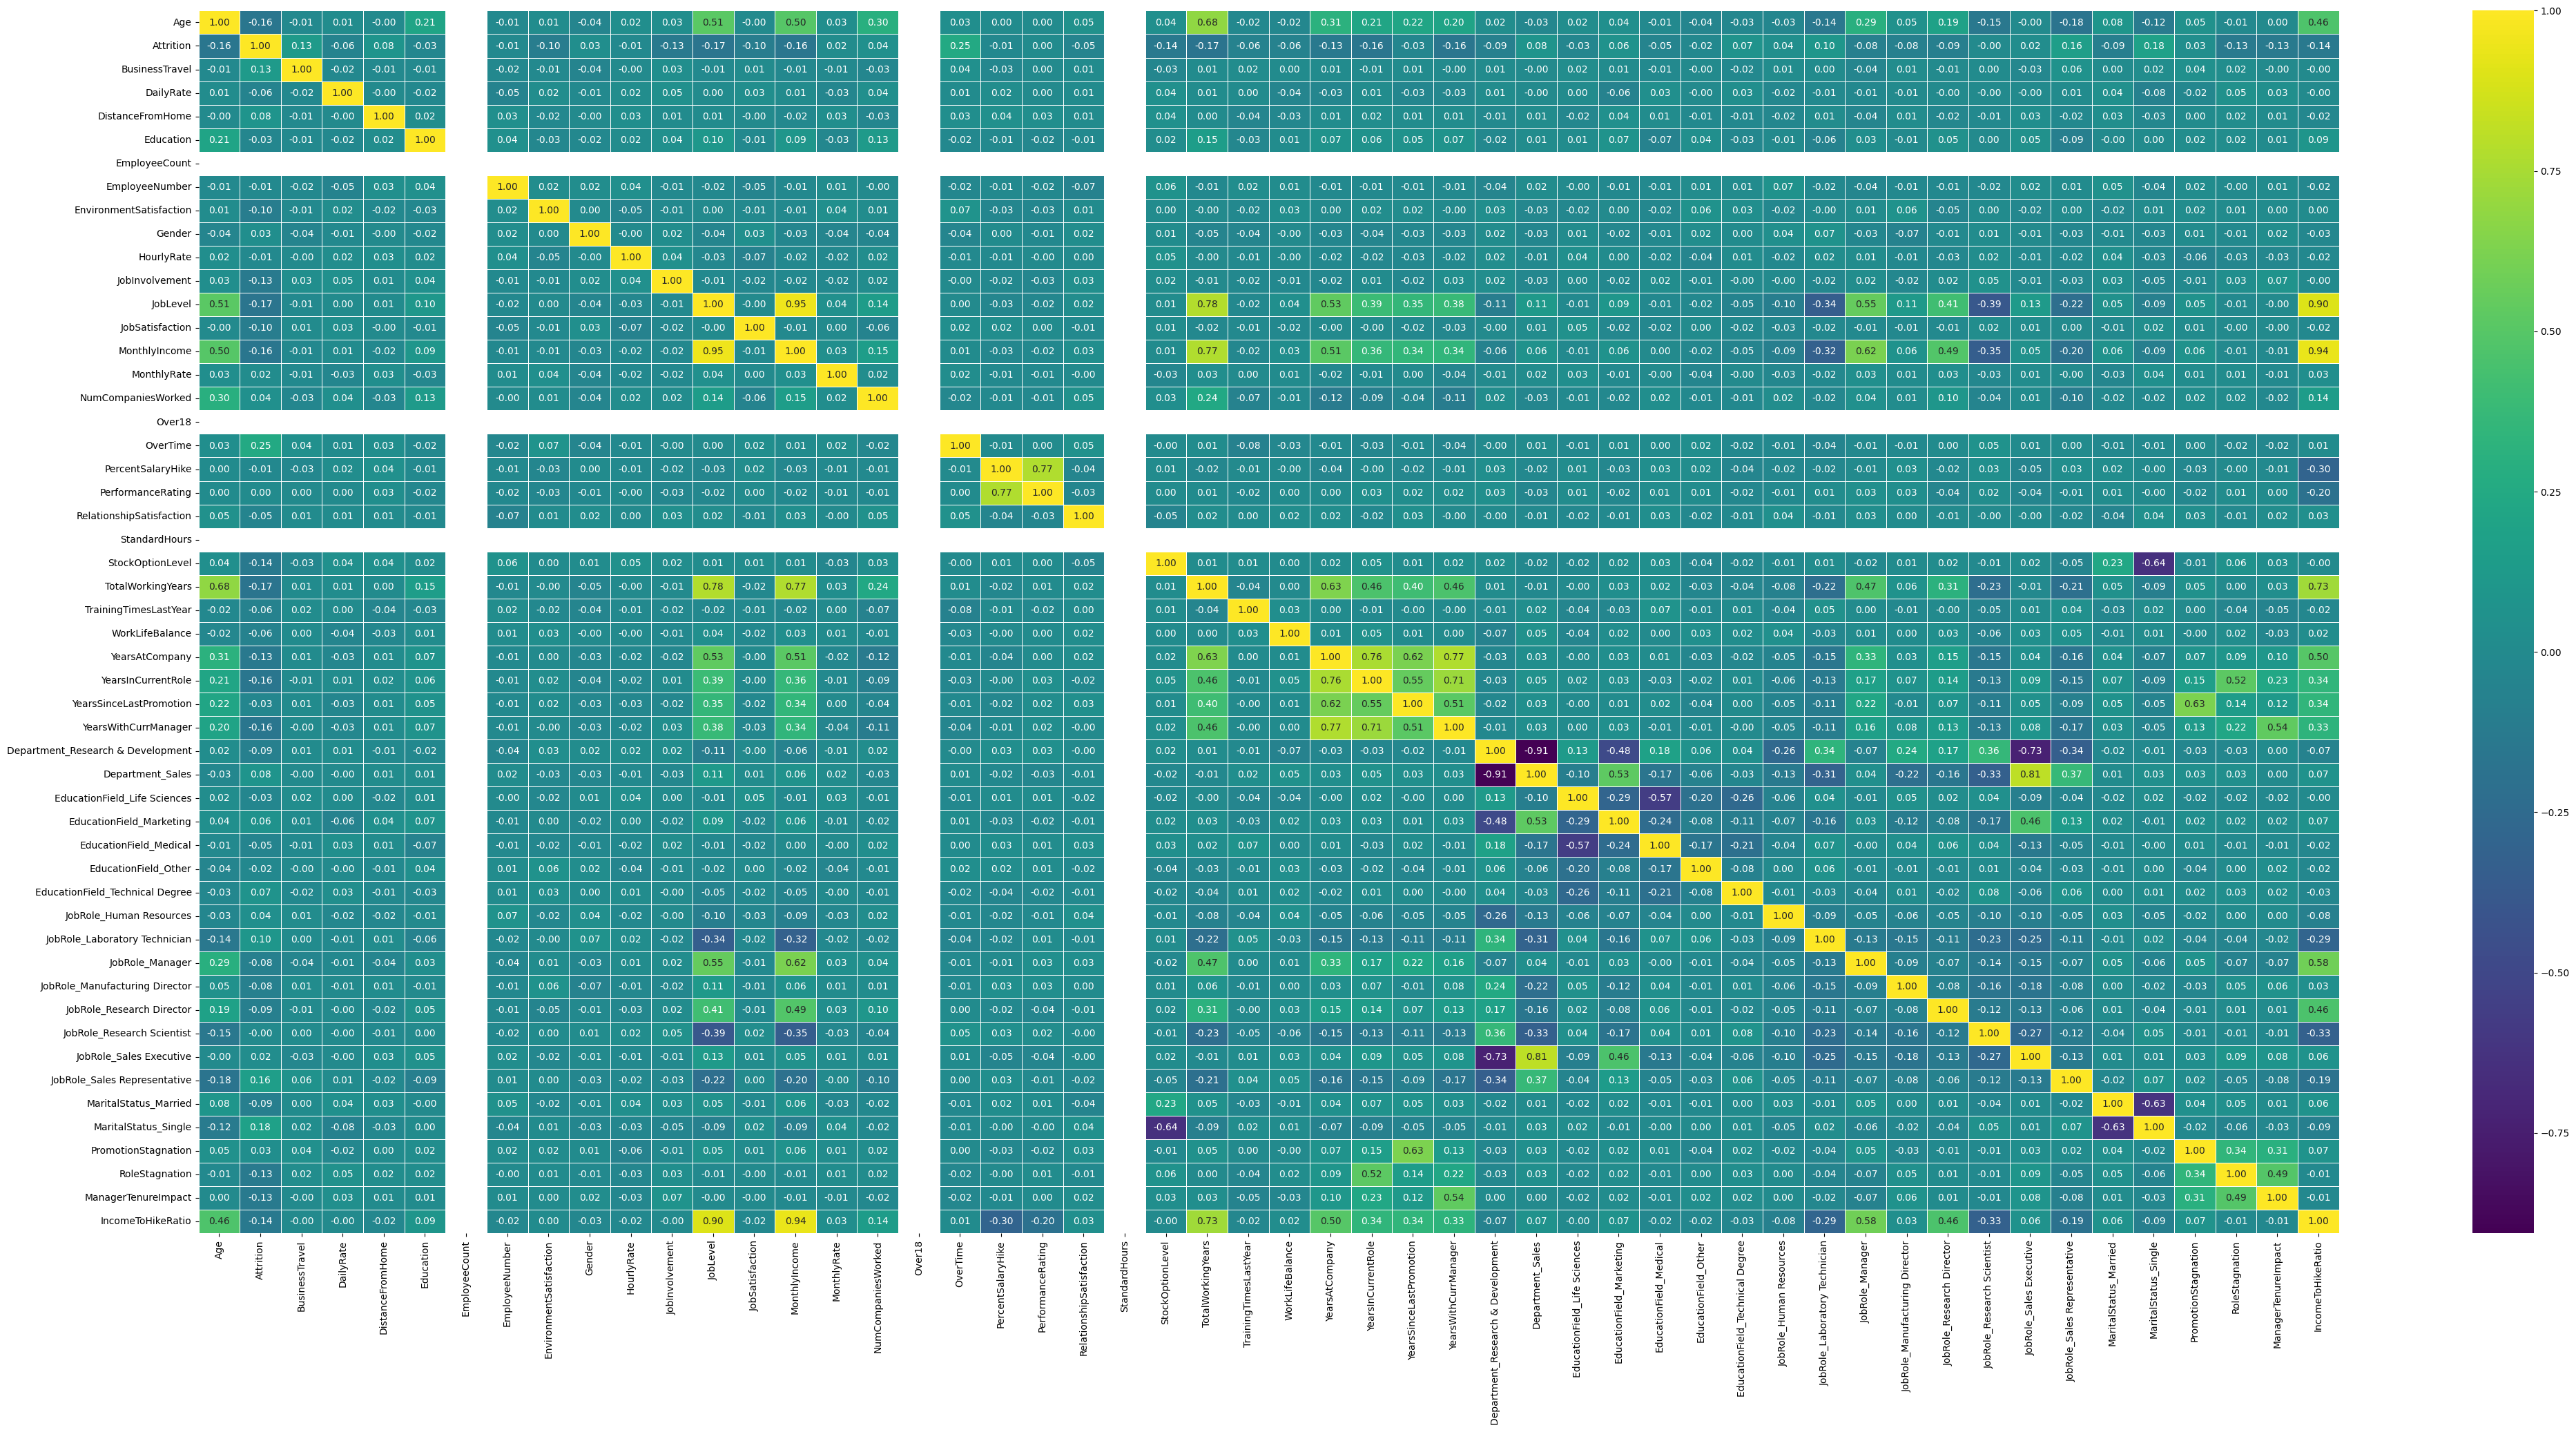

In [16]:
df_label_encoded = df.apply(lambda col: LabelEncoder().fit_transform(col) if col.dtype == 'object' else col)
correlation_matrix = df_label_encoded.corr()
plt.figure(figsize=(50, 23))
sns.heatmap(correlation_matrix, annot=True, cmap='viridis', fmt=".2f", linewidths=0.5)
plt.show()

Focus to key variables related to attrition

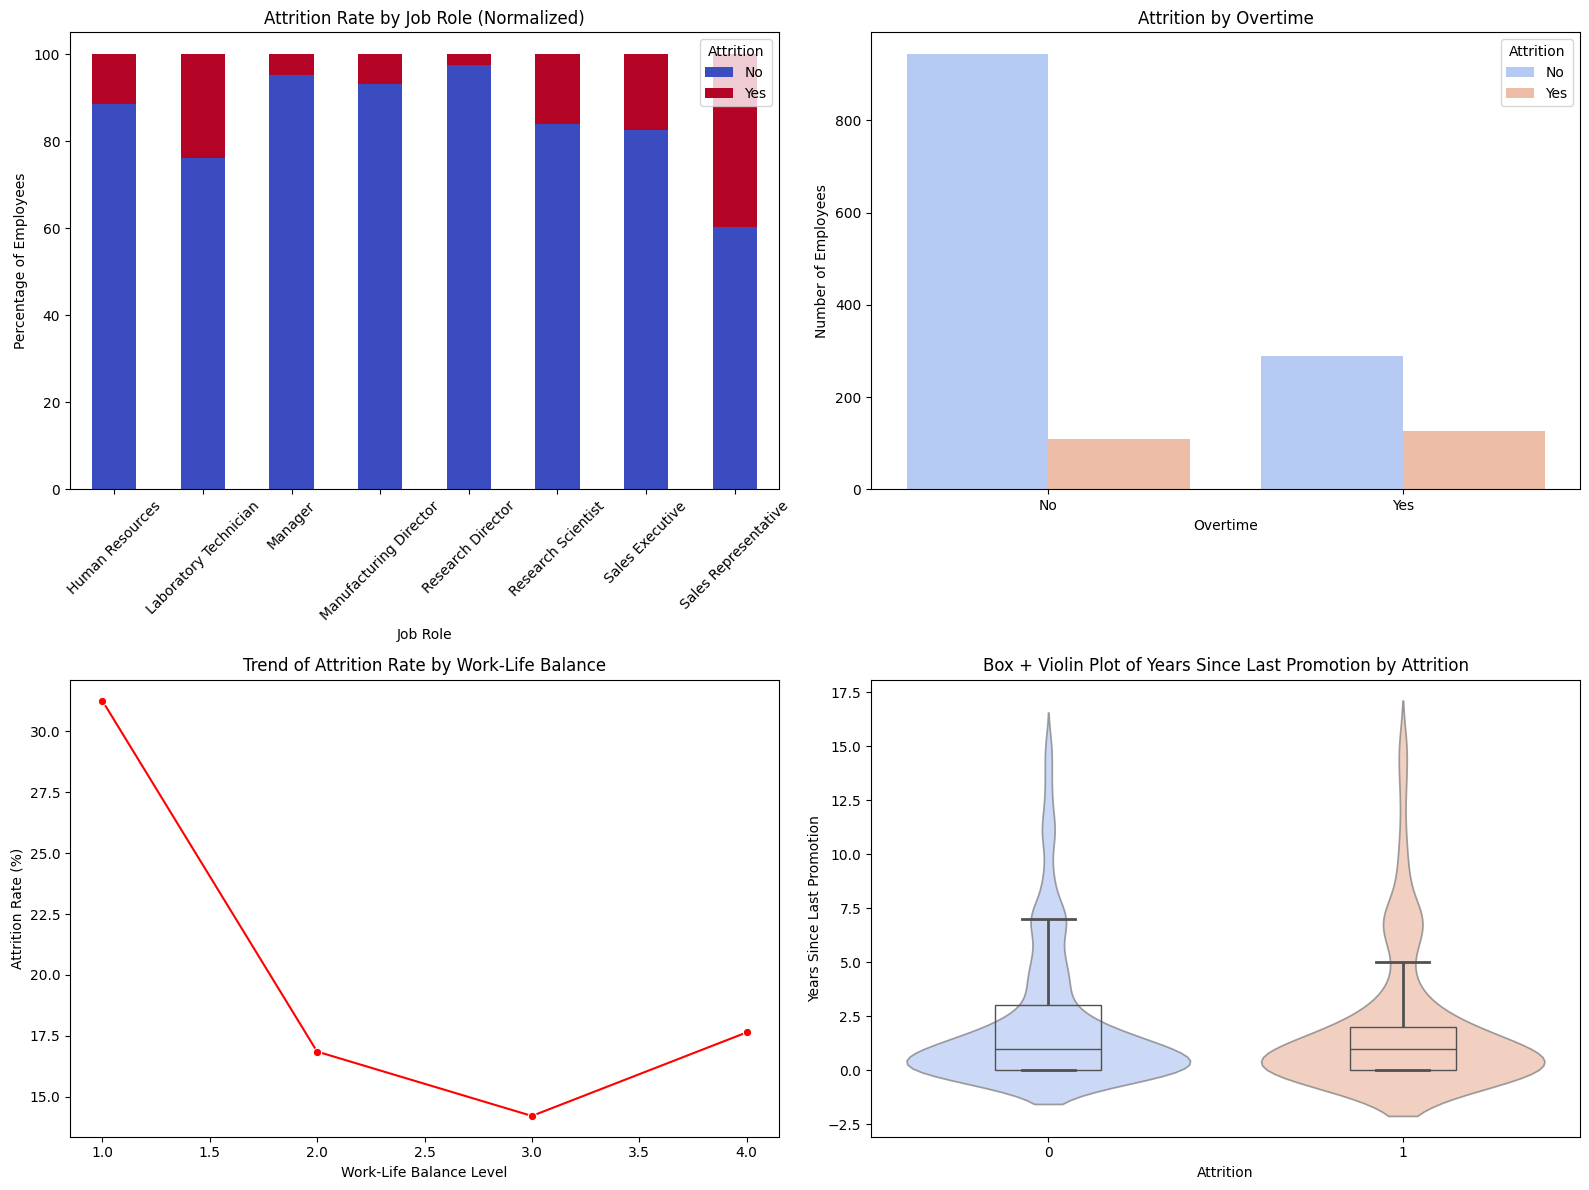

In [17]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))
_sub_df = df[['Attrition']].copy()
_sub_df['JobRole'] = df.filter(like='JobRole_').idxmax(axis=1).str.replace('JobRole_', '')
_sub_df['Attrition'] = _sub_df['Attrition'].replace({1: 'Yes', 0: 'No'}).astype('category')
_sub_df['JobRole'] = _sub_df['JobRole'].astype('category')
jobrole_attrition = _sub_df.groupby('JobRole')['Attrition'].value_counts(normalize=True).unstack() * 100
jobrole_attrition.plot(kind='bar', stacked=True, ax=axes[0, 0], colormap="coolwarm")
axes[0, 0].set_xlabel("Job Role")
axes[0, 0].set_ylabel("Percentage of Employees")
axes[0, 0].set_title("Attrition Rate by Job Role (Normalized)")
axes[0, 0].legend(title="Attrition", labels=['No', 'Yes'])
axes[0, 0].tick_params(axis='x', rotation=45)
_sub_df = df[['OverTime', 'Attrition']].copy()
_sub_df['Attrition'] = _sub_df['Attrition'].replace({1: 'Yes', 0: 'No'}).astype('category')
_sub_df['OverTime'] = _sub_df['OverTime'].replace({1: 'Yes', 0: 'No'}).astype('category')
sns.countplot(x=_sub_df['OverTime'], hue=_sub_df['Attrition'], palette='coolwarm', ax=axes[0, 1])
axes[0, 1].set_xlabel("Overtime")
axes[0, 1].set_ylabel("Number of Employees")
axes[0, 1].set_title("Attrition by Overtime")
axes[0, 1].legend(title="Attrition", labels=['No', 'Yes'])
attrition_rates = df.groupby('WorkLifeBalance')['Attrition'].mean() * 100
sns.lineplot(x=attrition_rates.index, y=attrition_rates.values, marker="o", color="red", ax=axes[1, 0])
axes[1, 0].set_xlabel("Work-Life Balance Level")
axes[1, 0].set_ylabel("Attrition Rate (%)")
axes[1, 0].set_title("Trend of Attrition Rate by Work-Life Balance")
sns.violinplot(x=df['Attrition'], y=df['YearsSinceLastPromotion'], inner=None, palette="coolwarm", alpha=0.7, ax=axes[1, 1])
sns.boxplot(x=df['Attrition'], y=df['YearsSinceLastPromotion'], width=0.3, showcaps=True, 
            boxprops={'facecolor':'None'}, showfliers=False, 
            whiskerprops={'linewidth':2}, capprops={'linewidth':2}, ax=axes[1, 1])
axes[1, 1].set_xlabel("Attrition")
axes[1, 1].set_ylabel("Years Since Last Promotion")
axes[1, 1].set_title("Box + Violin Plot of Years Since Last Promotion by Attrition")
plt.tight_layout()
plt.show()

### Summary of EDA

Based on our univariate and bivariate EDA, several key patterns around attrition have emerged. Employees in roles like `Sales Representative` and `Laboratory Technician` tend to leave more frequently, suggesting certain job functions may face higher dissatisfaction or stress. Overtime work and poor work-life balance also strongly correlate with higher attrition rates, highlighting the impact of workload and employee well-being. These findings help shape our approach to modeling by identifying meaningful features such as job role, overtime, and work-life balance that could improve the accuracy of attrition prediction models moving forward.

### DF Feature Set for Objective 1

In [11]:
categorical_cols = df.select_dtypes(include=['object']).columns
print("Categorical Columns:", list(categorical_cols))

Categorical Columns: []


In [12]:
Scaler = StandardScaler()
df_copy = df.copy()
y_attrition = df_copy.pop('Attrition')
X_nn = Scaler.fit_transform(df_copy)
X_nn = pd.DataFrame(X_nn, columns=df_copy.columns)

selector = SelectKBest(mutual_info_classif, k=30)
X_selected = selector.fit_transform(X_nn, y_attrition)

selected_columns = X_nn.columns[selector.get_support()]
X_selected_attrition = pd.DataFrame(X_selected, columns=selected_columns)

smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_selected_attrition, y_attrition)

df_attrition_focus = pd.concat([pd.DataFrame(X_resampled, columns=selected_columns), 
                                pd.Series(y_resampled, name='Attrition')], axis=1)

In [13]:
X_train_obj1, X_test_obj1, y_train_obj1, y_test_obj1 = train_test_split(X_resampled, y_resampled , test_size=0.2, random_state=42,stratify=y_resampled)

In [14]:
X_train_obj1.head()

,Age,DistanceFromHome,Education,HourlyRate,JobInvolvement,JobLevel,MonthlyIncome,NumCompaniesWorked,OverTime,RelationshipSatisfaction,...,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Research Director,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,RoleStagnation,ManagerTenureImpact,IncomeToHikeRatio
2358,-1.104666,1.611657,0.085049,-1.133779,0.379672,-0.961486,-0.873920,-0.678049,0.299384,0.266233,...,-0.191498,2.162331,-0.273059,-0.239904,-0.244625,-0.080229,-0.685565,1.270985,-1.669441,-0.915005
434,-0.648668,-0.023755,-1.868426,-1.618459,0.379672,0.845911,0.880739,-0.678049,-0.628241,1.191438,...,-0.191498,-0.462464,-0.273059,-0.239904,-0.244625,-0.918921,-0.685565,0.111991,0.169623,-0.075853
1101,-0.539166,-0.517332,-0.891688,0.054562,-1.026167,-0.057788,-0.132785,0.122861,-0.628241,-1.584178,...,-0.191498,-0.462464,-0.273059,-0.239904,-0.244625,1.088232,-0.685565,-1.311915,0.465187,0.104399
567,-0.320163,-0.887515,0.085049,-0.289883,0.379672,-0.057788,-0.048643,-0.678049,-0.628241,0.266233,...,-0.191498,-0.462464,-0.273059,-0.239904,-0.244625,-0.918921,1.458650,0.768754,0.322879,-0.472771
545,-0.758170,2.197341,2.038524,1.629171,0.379672,-0.057788,-0.254747,1.724681,-0.628241,1.191438,...,-0.191498,-0.462464,-0.273059,-0.239904,-0.244625,-0.918921,-0.685565,0.894312,0.945479,-0.626682


### DF Feature Set for Objective 2

In [18]:
obj2_df = df.copy()

# One-Hot Encoding for Non-Ordinal Categorical Columns
# These columns have more than 2 unique values
obj2_df = pd.get_dummies(obj2_df, 
                         columns=['BusinessTravel'], 
                         drop_first=True)  # drop_first=True prevents multicollinearity

# Label Encoding for Binary Categorical Columns
# These columns have exactly 2 unique values
binary_cols = ['Attrition', 'Gender', 'OverTime']
le = LabelEncoder()

for col in binary_cols:
    obj2_df[col] = le.fit_transform(obj2_df[col])

# Drop Columns That Are Not Useful
# "Over18" has only one unique value ("Y"), so it is useless for ML
obj2_df.drop(columns=['Over18'], inplace=True)

# Ensure All Data is Numeric
# Convert everything to numeric types to prevent errors in ML models
obj2_df = obj2_df.apply(pd.to_numeric, errors='coerce')

obj2_df = obj2_df.astype(int)

# Check Final Data Types
display(obj2_df.dtypes)

# Display first few rows to verify
display(obj2_df.head())

# create new column to measure high potential employees for promotion
obj2_df['high_potential'] = ((obj2_df['PerformanceRating'] > 2) &
                            (obj2_df['TrainingTimesLastYear'] > 2) & 
                            (obj2_df['YearsAtCompany'] > 2)).astype(int)

# features & label
# Option 1: Remove the columns used to create the target
X_xgboost = obj2_df.drop(columns=['high_potential', 'PerformanceRating', 'TrainingTimesLastYear', 'YearsAtCompany'])
y_xgboost = obj2_df['high_potential']

# feature selection
selector = SelectKBest(score_func=f_classif, k=10)
X_selected_xgboost = selector.fit_transform(X_xgboost, y_xgboost)
selected_features = X_xgboost.columns[selector.get_support()]

cleaned_selected_df = obj2_df[selected_features.tolist() + ["high_potential"]]
print(cleaned_selected_df['high_potential'].value_counts())

Age                                  int64
Attrition                            int64
DailyRate                            int64
DistanceFromHome                     int64
Education                            int64
EmployeeCount                        int64
EmployeeNumber                       int64
EnvironmentSatisfaction              int64
Gender                               int64
HourlyRate                           int64
JobInvolvement                       int64
JobLevel                             int64
JobSatisfaction                      int64
MonthlyIncome                        int64
MonthlyRate                          int64
NumCompaniesWorked                   int64
OverTime                             int64
PercentSalaryHike                    int64
PerformanceRating                    int64
RelationshipSatisfaction             int64
StandardHours                        int64
StockOptionLevel                     int64
TotalWorkingYears                    int64
TrainingTim

,Age,Attrition,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,...,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,PromotionStagnation,RoleStagnation,ManagerTenureImpact,IncomeToHikeRatio,BusinessTravel_1,BusinessTravel_2
0,41,1,1102,1,2,1,1,2,0,94,...,1,0,0,1,0,0,0,544,1,0
1,49,0,279,8,1,1,2,3,1,61,...,0,0,1,0,0,0,0,223,0,1
2,37,1,1373,2,2,1,4,4,1,92,...,0,0,0,1,0,0,0,139,1,0
3,33,0,1392,3,4,1,5,4,0,56,...,0,0,1,0,0,0,0,264,0,1
4,27,0,591,2,1,1,7,1,1,40,...,0,0,1,0,1,1,1,289,1,0


high_potential
0    853
1    617
Name: count, dtype: int64


### DF Feature set for Objective 3

In [16]:
obj3_df = df.copy() 

# Encode target (Attrition: Yes = 1, No = 0) 
obj3_df['Attrition'] = LabelEncoder().fit_transform(obj3_df['Attrition']) 

# Use OverTime as a simulated treatment variable (Yes = 1, No = 0) 
obj3_df['Treatment'] = LabelEncoder().fit_transform(obj3_df['OverTime']) 

# Drop unused columns 
obj3_df.drop(columns=['OverTime', 'EmployeeCount', 'EmployeeNumber', 'StandardHours', 'Over18'], inplace=True) 

# One-hot encode categorical variables 
obj3_df = pd.get_dummies(obj3_df, drop_first=True)

In [17]:
X_uplift = obj3_df.drop(columns=["Attrition", "Treatment"]) 
y_uplift = obj3_df["Attrition"] 
T = obj3_df["Treatment"] 

selector = SelectKBest(score_func=lambda X, y: mutual_info_classif(X, y, random_state=42), k=20)
selector.fit(X_uplift, y_uplift)

selected_features_uplift = X_uplift.columns[selector.get_support()].tolist()
X_selected_uplift = X_uplift[selected_features_uplift]

# Split dataset 
X_train_obj3, X_test_obj3, y_train_obj3, y_test_obj3, T_train_obj3, T_test_obj3 = train_test_split(
    X_selected_uplift, y_uplift, T, test_size=0.2, random_state=42, stratify=y_uplift
)

(
    selected_features_uplift
)


['Age',
 'Education',
 'EnvironmentSatisfaction',
 'JobInvolvement',
 'JobLevel',
 'MonthlyIncome',
 'StockOptionLevel',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'WorkLifeBalance',
 'YearsAtCompany',
 'YearsWithCurrManager',
 'Department_Research & Development',
 'EducationField_Technical Degree',
 'JobRole_Sales Representative',
 'MaritalStatus_Single',
 'PromotionStagnation',
 'RoleStagnation',
 'ManagerTenureImpact',
 'IncomeToHikeRatio']

# VI. Approach and Methodology

This study applies deep learning, gradient boosting, and explainability techniques to predict employee attrition, identify high-potential employees for promotion, and optimize retention strategies. A neural network (TensorFlow/Keras) is used for attrition prediction, leveraging its ability to capture complex, non-linear relationships in employee data, while SHAP (Shapley Additive Explanations) is applied to identify key factors influencing attrition, providing HR teams with insights into why employees leave. For promotion identification, XGBoost is utilized due to its efficiency with structured data and its ability to handle feature interactions, with promotion likelihood scores derived from classification probabilities to guide HR decisions. In optimizing retention strategies,  uplift modeling predicts which employees will respond positively to specific strategies. 

# VII. Modeling

## Neural Network Model

In [18]:
input_shape = [X_train_obj1.shape[1]]

In [19]:
neural_network_model = keras.Sequential([
    layers.Dense(32, activation='relu', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.Dropout(0),

    layers.Dense(16, activation="relu"), 
    layers.BatchNormalization(),
    layers.Dropout(0),

    layers.Dense(1, activation="sigmoid")

])

neural_network_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

neural_network_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,729 (6.75 KB)

 Trainable params: 1,633 (6.38 KB)

 Non-trainable params: 96 (384.00 B)

### Initial model training and Prediction

In [20]:
class_weights = class_weight.compute_class_weight(
    'balanced', classes=np.unique(y_train_obj1), y=y_train_obj1
)
class_weights = dict(enumerate(class_weights))

history = neural_network_model.fit(
    X_train_obj1, y_train_obj1,
    validation_data=(X_test_obj1, y_test_obj1),
    batch_size=32,
    epochs=100,
    class_weight=class_weights,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=10,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4209 - loss: 0.9296 - val_accuracy: 0.4514 - val_loss: 0.7918
Epoch 2/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4249 - loss: 0.8799 - val_accuracy: 0.4757 - val_loss: 0.7711
Epoch 3/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4697 - loss: 0.8240 - val_accuracy: 0.5202 - val_loss: 0.7445
Epoch 4/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5068 - loss: 0.7566 - val_accuracy: 0.5506 - val_loss: 0.7169
Epoch 5/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5280 - loss: 0.7391 - val_accuracy: 0.5830 - val_loss: 0.6919
Epoch 6/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5593 - loss: 0.7087 - val_accuracy: 0.6194 - val_loss: 0.6692
Epoch 7/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6075 - loss: 0.6664 - val_accuracy: 0.6538 - val_loss: 0.6507
Epoch 8/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6103 - loss: 0.6568 - val_accuracy: 0.6599 - v

In [21]:
train_loss, train_accuracy = neural_network_model.evaluate(X_train_obj1, y_train_obj1, verbose=1)
test_loss, test_accuracy = neural_network_model.evaluate(X_test_obj1, y_test_obj1, verbose=1)
print(
    "||================||============||============||\n"
    "|| Metrics        || Train      || Test       ||\n"
    "||================||============||============||\n"
    "|| Loss           || {:.4f}     || {:.4f}     ||\n"
    "|| Accuracy       || {:.4f}     || {:.4f}     ||\n"
    "||================||============||============||".format(train_loss, test_loss, train_accuracy, test_accuracy)
)

62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8865 - loss: 0.2876
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8479 - loss: 0.4182 
||================||============||============||
|| Metrics        || Train      || Test       ||
||================||============||============||
|| Loss           || 0.2883     || 0.3928     ||
|| Accuracy       || 0.8849     || 0.8502     ||
||================||============||============||


In [22]:
def plot_classification_report(report_df, title):
    plt.figure(figsize=(8, 6))
    sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap='Blues', fmt='.2f')
    plt.title(title)
    plt.ylabel('Metrics')
    plt.xlabel('Labels')
    plt.show()

def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y_true), yticklabels=np.unique(y_true))
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title(title)
    plt.show()

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 800us/step


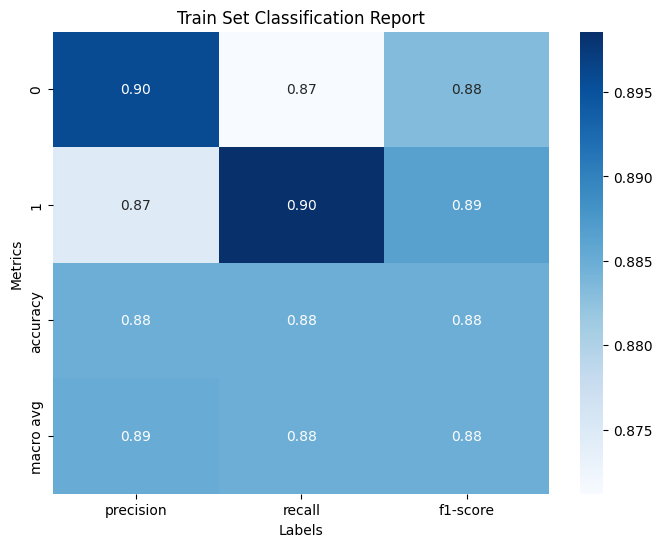

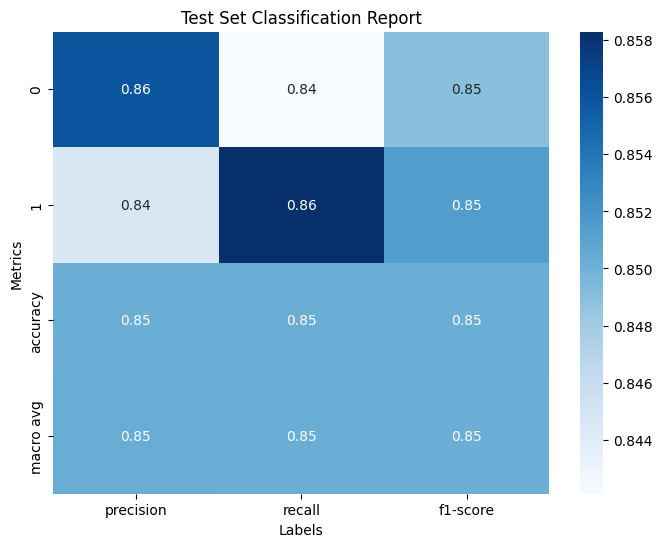

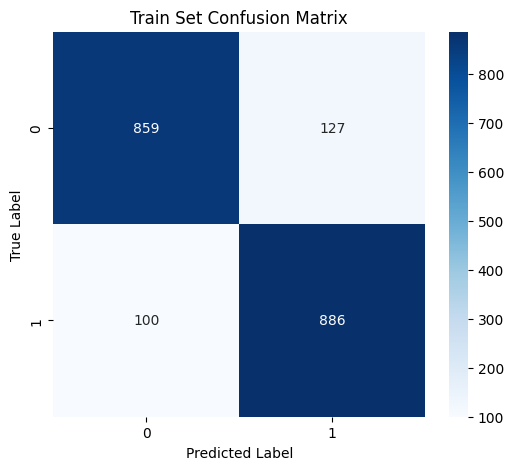

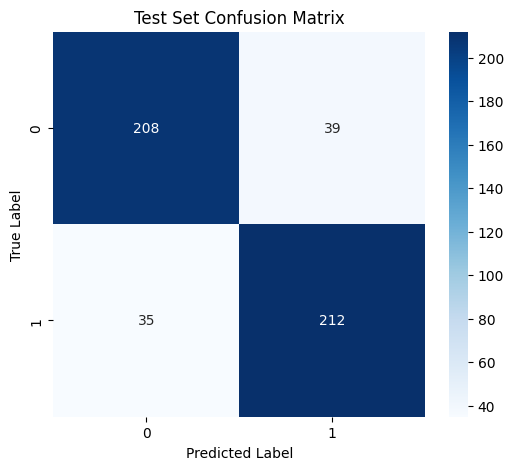

In [23]:
y_pred_prob = neural_network_model.predict(X_test_obj1)
y_pred = (y_pred_prob > 0.5).astype(int)

y_pred_prob_1 = neural_network_model.predict(X_train_obj1)
y_pred_1 = (y_pred_prob_1 > 0.5).astype(int)

train_report = classification_report(y_train_obj1, y_pred_1, output_dict=True)
test_report = classification_report(y_test_obj1, y_pred, output_dict=True)

train_df = pd.DataFrame(train_report).T
test_df = pd.DataFrame(test_report).T

plot_classification_report(train_df, "Train Set Classification Report")
plot_classification_report(test_df, "Test Set Classification Report")

plot_confusion_matrix(y_train_obj1, y_pred_1, "Train Set Confusion Matrix")
plot_confusion_matrix(y_test_obj1, y_pred, "Test Set Confusion Matrix")

The initial model results indicate a discrepancy between training and test performance, suggesting potential overfitting. To address this, we will proceed with hyperparameter tuning to improve generalization and overall model performance.

In [24]:
def set_seeds(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds()

def objective(trial):
    units_1 = 64
    units_2 = 32
    units_3 = 16
    dropout_rate = trial.suggest_float("dropout", 0.4, 0.8)
    learning_rate = trial.suggest_loguniform("lr", 1e-4, 1e-1)
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])
    epochs = trial.suggest_int("epochs", 20, 80, step=10)
    reg_strength = trial.suggest_loguniform("reg_strength", 1e-3, 1e-1)
    
    class_weights = compute_class_weight(
        class_weight='balanced', classes=np.unique(y_train_obj1), y=y_train_obj1
    )
    class_weights = dict(enumerate(class_weights))

    model = keras.Sequential([
        layers.Dense(units_1, activation='relu', input_shape=input_shape, kernel_regularizer=regularizers.l2(reg_strength)),
        layers.BatchNormalization(),
        layers.Dropout(dropout_rate),

        layers.Dense(units_2, activation="relu", kernel_regularizer=regularizers.l2(reg_strength)),
        layers.BatchNormalization(),
        layers.Dropout(dropout_rate),

        layers.Dense(units_3, activation="relu", kernel_regularizer=regularizers.l2(reg_strength)),
        layers.BatchNormalization(),
        layers.Dropout(dropout_rate),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="binary_crossentropy", metrics=["accuracy"])

    history = model.fit(
        X_train_obj1, y_train_obj1,
        validation_data=(X_test_obj1, y_test_obj1),
        batch_size=batch_size,
        epochs=epochs,
        class_weight=class_weights,
        verbose=0,
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True,
        min_delta=0.0005)]
    )

    return min(history.history["val_loss"])

In [25]:
study_nn = optuna.create_study(direction="minimize")
study_nn.optimize(objective, n_trials=100, n_jobs=-1)

best_params = study_nn.best_trial.params
print("Best Parameters:", best_params)

[I 2025-04-02 03:29:02,322] A new study created in memory with name: no-name-d8068b93-4263-4194-9a1f-db1b559a6cc7
[I 2025-04-02 03:29:24,400] Trial 2 finished with value: 0.6172432899475098 and parameters: {'dropout': 0.44732938107544373, 'lr': 0.003749192390936859, 'batch_size': 32, 'epochs': 50, 'reg_strength': 0.04331979456190953}. Best is trial 2 with value: 0.6172432899475098.
[I 2025-04-02 03:29:29,913] Trial 1 finished with value: 0.7891864776611328 and parameters: {'dropout': 0.7728894321893479, 'lr': 0.019747391916550297, 'batch_size': 16, 'epochs': 30, 'reg_strength': 0.04355840700532717}. Best is trial 2 with value: 0.6172432899475098.
[I 2025-04-02 03:29:34,002] Trial 3 finished with value: 0.6029582023620605 and parameters: {'dropout': 0.5292979537226343, 'lr': 0.0004250863445793526, 'batch_size': 64, 'epochs': 60, 'reg_strength': 0.026340563292696503}. Best is trial 3 with value: 0.6029582023620605.
[I 2025-04-02 03:29:35,350] Trial 0 finished with value: 0.90155929327011

In [26]:
final_model = keras.Sequential([
    layers.Dense(32, activation="relu", input_shape=(X_train_obj1.shape[1],),
                 kernel_regularizer=regularizers.l2(best_params["reg_strength"])),
    layers.Dropout(best_params["dropout"]),

    layers.Dense(16, activation="relu",
                 kernel_regularizer=regularizers.l2(best_params["reg_strength"])),  
    layers.Dropout(best_params["dropout"]),
    layers.Dense(8, activation="relu",
                 kernel_regularizer=regularizers.l2(best_params["reg_strength"])),  
    layers.Dropout(best_params["dropout"]),

    layers.Dense(1, activation="sigmoid")
])

final_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=best_params["lr"]),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

final_model.fit(X_train_obj1, y_train_obj1, epochs=best_params["epochs"], 
                batch_size=best_params["batch_size"],class_weight=class_weights, verbose=1)

train_loss, train_accuracy = final_model.evaluate(X_train_obj1, y_train_obj1, verbose=1)
test_loss, test_accuracy = final_model.evaluate(X_test_obj1, y_test_obj1, verbose=1)
print(
    "||================||============||============||\n"
    "|| Metrics        || Train      || Test       ||\n"
    "||================||============||============||\n"
    "|| Loss           || {:.4f}     || {:.4f}     ||\n"
    "|| Accuracy       || {:.4f}     || {:.4f}     ||\n"
    "||================||============||============||".format(train_loss, test_loss, train_accuracy, test_accuracy)
)

Epoch 1/80
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5069 - loss: 0.9533
Epoch 2/80
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5303 - loss: 0.8201 
Epoch 3/80
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5387 - loss: 0.7976 
Epoch 4/80
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5679 - loss: 0.7889 
Epoch 5/80
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5835 - loss: 0.7565 
Epoch 6/80
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6086 - loss: 0.7517 
Epoch 7/80
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6295 - loss: 0.7187 
Epoch 8/80
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6601 - loss: 0.7079
Epoch 9/80
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6712 - loss: 0.6969 
Epoch 10/80
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6945 - loss: 0.6837 
Epoch 11/80
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6985 - loss: 0.6633
Epoch 12/80
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6

### Initial XGBoostClassifier Model

In [27]:
X_xgb = cleaned_selected_df.drop('high_potential', axis=1).values
y_xgb = cleaned_selected_df['high_potential'].values

xgBoost = XGBClassifier(
    max_depth=5,           
    learning_rate=0.01,    
    n_estimators=300,      
    subsample=0.9,         
    colsample_bytree=0.9,  
    gamma=0.1,            
)

# 5-fold cross validation
kf_xgb = KFold(n_splits=5, shuffle=True, random_state=1)

# get training and testing accuracies
cv_results = cross_validate(xgBoost, X_xgb, y_xgb, cv=kf_xgb, return_train_score=True, scoring='accuracy')
train_acc_xgb = cv_results['train_score']
test_acc_xgb = cv_results['test_score']

# compute accuracy for each fold
cv_scores_xgb = cross_val_score(xgBoost, X_xgb, y_xgb, cv=kf_xgb, scoring='accuracy')

# make predictions
y_pred_xgb = cross_val_predict(xgBoost, X_xgb, y_xgb, cv=kf_xgb)

# Check Overfitting: Train vs Validation Accuracy
print(f"Training Accuracy per fold: {train_acc_xgb}")
print(f"Testing Accuracy per fold: {test_acc_xgb}")
print(f"Mean Training Accuracy: {np.mean(train_acc_xgb) * 100:.4f}%")
print(f"Mean Testing Accuracy: {np.mean(test_acc_xgb) * 100:.4f}%")


Training Accuracy per fold: [0.7585034  0.76360544 0.76530612 0.74659864 0.76870748]
Testing Accuracy per fold: [0.60884354 0.63265306 0.63265306 0.65646259 0.6122449 ]
Mean Training Accuracy: 76.0544%
Mean Testing Accuracy: 62.8571%


In [28]:
print("\n**Classification Report (SGBoostClassifier - 5-Fold CV)**")
print(classification_report(y_xgb, y_pred_xgb))

roc_auc_sgd = roc_auc_score(y_xgb, y_pred_xgb)
print(f"ROC-AUC Score: {roc_auc_sgd:.4f}")

unique, counts = np.unique(y_pred_xgb, return_counts=True)
class_distribution_sgd = {int(label): int(count) for label, count in zip(unique, counts)}
print("\n**Class Distribution in Predictions (SGBoostClassifier - 5-Fold CV)**")
for label, count in class_distribution_sgd.items():
    print(f"Class {label}: {count}")


**Classification Report (SGBoostClassifier - 5-Fold CV)**
              precision    recall  f1-score   support

           0       0.75      0.54      0.63       853
           1       0.54      0.76      0.63       617

    accuracy                           0.63      1470
   macro avg       0.65      0.65      0.63      1470
weighted avg       0.66      0.63      0.63      1470

ROC-AUC Score: 0.6461

**Class Distribution in Predictions (SGBoostClassifier - 5-Fold CV)**
Class 0: 609
Class 1: 861


### Tuned XGBoostClassifier Model

In [29]:
from sklearn.model_selection import GridSearchCV, cross_validate, KFold
from xgboost import XGBClassifier
import numpy as np

# Define the hyperparameter grid
param_grid = {
    'max_depth': [3, 5],       
    'learning_rate': [0.01, 0.05, 0.1],  
    'n_estimators': [100, 300],   
    'subsample': [0.7, 0.8],  
    'colsample_bytree': [0.7, 0.8],  
    'gamma': [0.1, 0.3, 0.5], 
    'reg_lambda': [0.5, 1.0],  
    'reg_alpha': [0, 0.5]  
}

X_xgb = cleaned_selected_df.drop('high_potential', axis=1).values
y_xgb = cleaned_selected_df['high_potential'].values

# Initialize XGBoost
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=1)

# Perform Grid Search with 5-Fold Cross Validation
grid_search = GridSearchCV(xgb_model, param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(X_xgb, y_xgb)

# Get the best hyperparameters
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print("\nBest Hyperparameters:", best_params)
print(f"Best Grid Search Test Accuracy: {best_score * 100:.4f}%\n")

# Train the model using the best hyperparameters
best_xgb = XGBClassifier(**best_params, use_label_encoder=False, eval_metric='logloss', random_state=1)

# Perform 5-Fold Cross Validation
kf_xgb = KFold(n_splits=5, shuffle=True, random_state=1)

cv_results = cross_validate(best_xgb, X_xgb, y_xgb, cv=kf_xgb, return_train_score=True, scoring='accuracy')

# Extract train & test accuracies per fold
train_acc_xgb = cv_results['train_score']
test_acc_xgb = cv_results['test_score']

# new predictions
y_pred_best_xgb = cross_val_predict(best_xgb, X_xgb, y_xgb, cv=kf_xgb)

# Print results
print("Training Accuracy per Fold:", train_acc_xgb)
print("Testing Accuracy per Fold:", test_acc_xgb)
print(f"Mean Training Accuracy: {np.mean(train_acc_xgb) * 100:.4f}%")
print(f"Mean Testing Accuracy: {np.mean(test_acc_xgb) * 100:.4f}%")

Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/root/venv/lib/python3.11/site-packages/xgboost/training.py:183: UserWarning: [03:44:05] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/root/venv/lib/python3.11/site-packages/xgboost/training.py:183: UserWarning: [03:44:05] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/root/venv/lib/python3.11/site-packages/xgboost/training.py:183: UserWarning: [03:44:05] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/root/venv/lib/python3.11/site-packages/xgboost/training.py:183: UserWarning: [03:44:05] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/root

In [30]:
print("\n**Classification Report (Best XGBoost - 5-Fold CV)**")
print(classification_report(y_xgb, y_pred_best_xgb))

roc_auc_best = roc_auc_score(y_xgb, y_pred_best_xgb)
print(f"ROC-AUC Score: {roc_auc_best:.4f}")

unique, counts = np.unique(y_pred_best_xgb, return_counts=True)
class_distribution_best = {int(label): int(count) for label, count in zip(unique, counts)}
print("\n**Class Distribution in Predictions (Best XGBoost - 5-Fold CV)**")
for label, count in class_distribution_best.items():
    print(f"Class {label}: {count}")


**Classification Report (Best XGBoost - 5-Fold CV)**
              precision    recall  f1-score   support

           0       0.74      0.55      0.63       853
           1       0.54      0.73      0.62       617

    accuracy                           0.63      1470
   macro avg       0.64      0.64      0.63      1470
weighted avg       0.66      0.63      0.63      1470

ROC-AUC Score: 0.6432

**Class Distribution in Predictions (Best XGBoost - 5-Fold CV)**
Class 0: 635
Class 1: 835


## Uplift Model

The Uplift (UL) model is a machine learning technique designed to estimate the incremental impact of a treatment or intervention--like a retention effort--on individual behavior, rather than just predicting outcomes. In the context of objective 3, it helps identify which employees are most likely to change their decision to stay if a specific retention strategy is applied. By targeting those who are most responsive to interventions, the UL model enables organizations to make smarter, more personalized decisions that effectively reduce turnover and improve overall employee satisfaction.

### Initial UL Model Training and Prediction

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 93, number of negative: 743
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000044 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 828
[LightGBM] [Info] Number of data points in the train set: 836, number of used features: 20
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.111244 -> initscore=-2.078097
[LightGBM] [Info] Start training from score -2.078097
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 97, number of negative: 243
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000062 seconds.
You can set `force_col_wise=true` to remove t

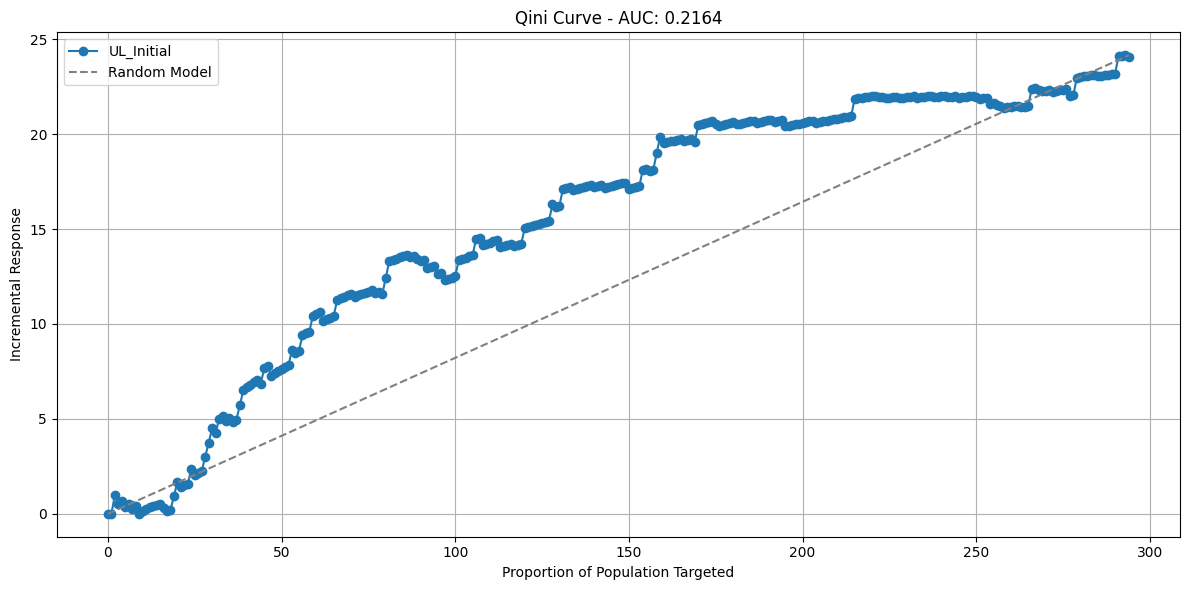

In [31]:
# # Define the base model for both treatment and control
# treatment_model = LGBMClassifier(random_state=42)
# control_model = LGBMClassifier(random_state=42)

# # Initialize the TwoModels uplift model (correct for version 0.5.1)
# UL_initial = TwoModels(
#     estimator_trmnt=treatment_model,
#     estimator_ctrl=control_model,
#     method='vanilla'  # Other options: 'ddr_control', 'ddr_treatment'
# )

# # Fit the model
# UL_initial.fit(
#     X=X_train_obj3[selected_features_uplift],
#     y=y_train_obj3,
#     treatment=T_train_obj3
# )

# uplift_preds = UL_initial.predict(X_test_obj3[selected_features]) 

# # Compute qini curve and score 
# qini_scores = qini_curve(y_test_obj3, uplift_preds, T_test_obj3) 
# qini_auc = qini_auc_score(y_test_obj3, uplift_preds, T_test_obj3)

# plt.figure(figsize=(12, 6)) 
# plt.plot(qini_scores[0], qini_scores[1], marker='o', label='UL_Initial') 
# plt.plot([0, len(y_test_obj3)], [0, max(qini_scores[1])], linestyle='--', color='gray', label='Random Model') 
# plt.xlabel('Proportion of Population Targeted') 
# plt.ylabel('Incremental Response') 
# plt.title(f'Qini Curve - AUC: {qini_auc:.4f}') 
# plt.legend() 
# plt.grid(True) 
# plt.tight_layout() 
# plt.show()

# Define the base model for both treatment and control
treatment_model = LGBMClassifier(random_state=42)
control_model = LGBMClassifier(random_state=42)

# Initialize the TwoModels uplift model (correct for version 0.5.1)
UL_initial = TwoModels(
    estimator_trmnt=treatment_model,
    estimator_ctrl=control_model,
    method='vanilla'  # Other options: 'ddr_control', 'ddr_treatment'
)

# Fit the model
UL_initial.fit(
    X=X_train_obj3[selected_features_uplift],
    y=y_train_obj3,
    treatment=T_train_obj3
)

uplift_preds = UL_initial.predict(X_test_obj3[selected_features_uplift]) 

# Compute qini curve and score 
qini_scores = qini_curve(y_test_obj3, uplift_preds, T_test_obj3) 
qini_auc = qini_auc_score(y_test_obj3, uplift_preds, T_test_obj3)

plt.figure(figsize=(12, 6)) 
plt.plot(qini_scores[0], qini_scores[1], marker='o', label='UL_Initial') 
plt.plot([0, len(y_test_obj3)], [0, max(qini_scores[1])], linestyle='--', color='gray', label='Random Model') 
plt.xlabel('Proportion of Population Targeted') 
plt.ylabel('Incremental Response') 
plt.title(f'Qini Curve - AUC: {qini_auc:.4f}') 
plt.legend() 
plt.grid(True) 
plt.tight_layout() 
plt.show()

The Qini curve shows how well the initial uplift model (UL_inital) can help identify which employees are more likely to stay if we take action--like adjusting work conditions or offering support. The blue line represents the model's ability to increase retention, while the gray dashed line shows what would happen if we targeted employees randomly. Since the blue line rises above the gray line, it means our model is doing a better job than guessing--it can pick up patterns in who responds positively to interventions. While the `AUC score (0.2164)` suggests there's still room to improve, this early result is promising and shows that we are currently in the right direction.

Classification Report:
              precision    recall  f1-score     support
0              0.866667  0.105263  0.187726  247.000000
1              0.162879  0.914894  0.276527   47.000000
accuracy       0.234694  0.234694  0.234694    0.234694
macro avg      0.514773  0.510078  0.232126  294.000000
weighted avg   0.754156  0.234694  0.201922  294.000000


<Figure size 1000x600 with 0 Axes>

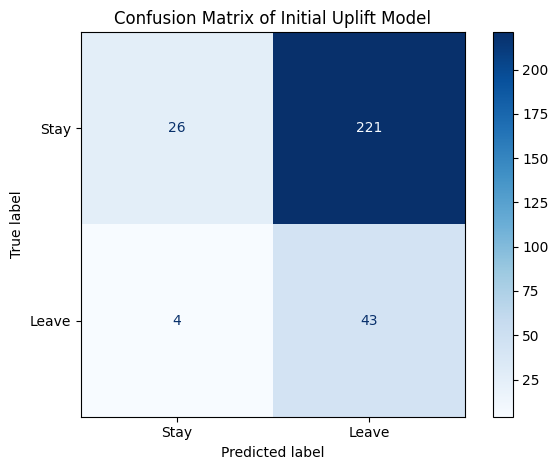

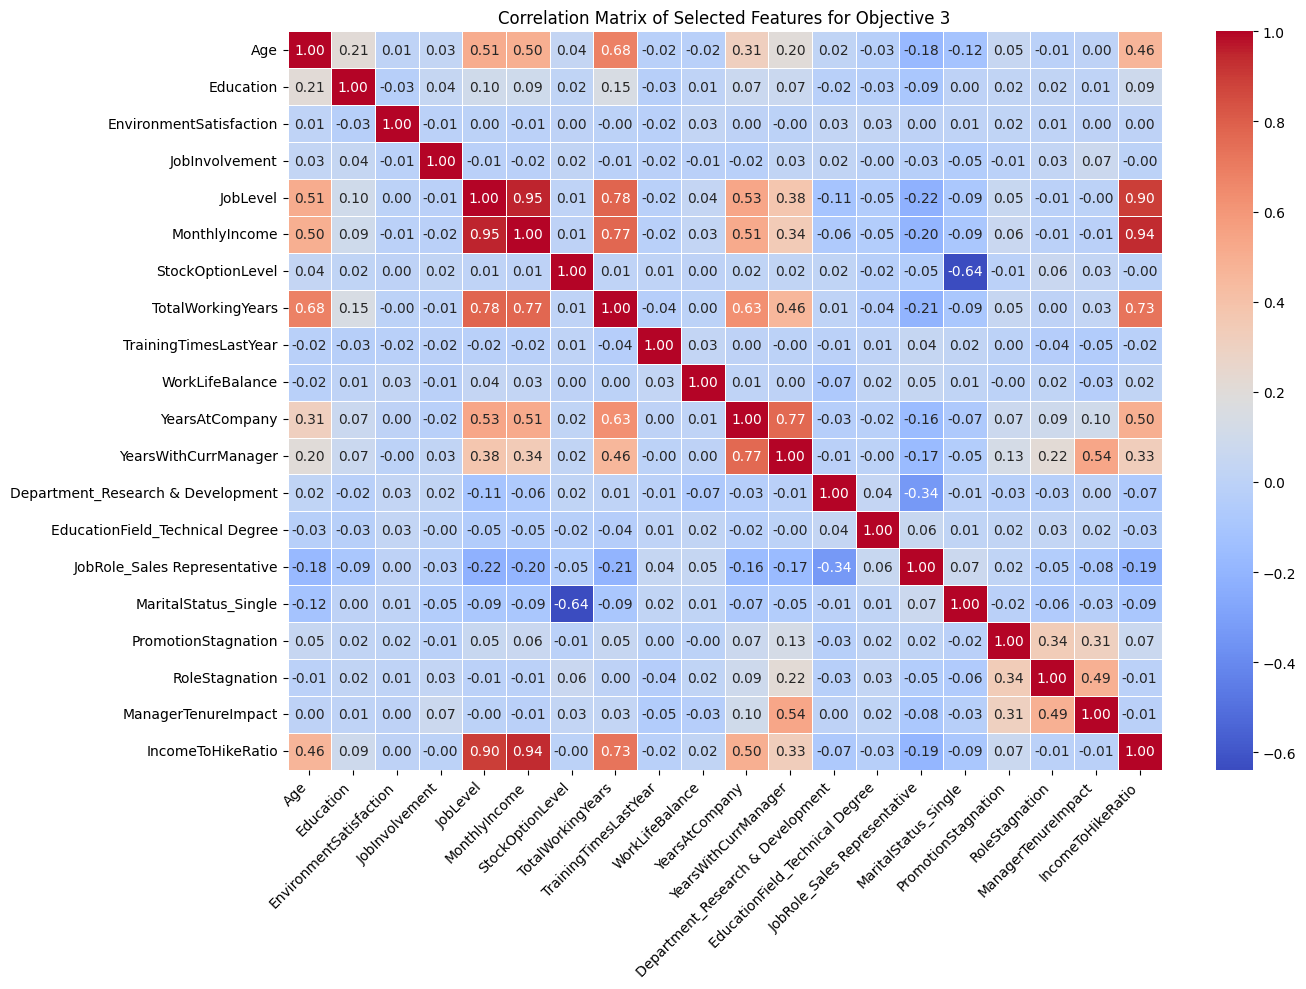

In [32]:
# # Classify as 1 (likely to respond to treatment)
# uplift_binary_preds = (uplift_preds > 0).astype(int)

# # Classification report 
# report = classification_report(y_test_obj3, uplift_binary_preds, output_dict=True) 
# report_df = pd.DataFrame(report).transpose() 

# print('Classification Report:')
# print(report_df)

# # Confusion matrix 
# conf_matrix = confusion_matrix(y_test_obj3, uplift_binary_preds) 
# disp = ConfusionMatrixDisplay(conf_matrix, display_labels=["Stay", "Leave"]) 

# # Correlation matrix for selected features 
# corr_matrix = X_selected[selected_features].corr()

# # Plot 
# plt.figure(figsize=(10, 6)) 
# disp.plot(cmap='Blues', values_format='d') 
# plt.title("Confusion Matrix of Initial Uplift Model") 
# plt.tight_layout() 
# plt.show() 

# plt.figure(figsize=(14, 10)) 
# sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5) 
# plt.title("Correlation Matrix of Selected Features for Objective 3") 
# plt.xticks(rotation=45, ha='right') 
# plt.yticks(rotation=0) 
# plt.tight_layout() 
# plt.show()

# Classify as 1 (likely to respond to treatment)
uplift_binary_preds = (uplift_preds > 0).astype(int)

# Classification report 
report = classification_report(y_test_obj3, uplift_binary_preds, output_dict=True) 
report_df = pd.DataFrame(report).transpose() 

print('Classification Report:')
print(report_df)

# Confusion matrix 
conf_matrix = confusion_matrix(y_test_obj3, uplift_binary_preds) 
disp = ConfusionMatrixDisplay(conf_matrix, display_labels=["Stay", "Leave"]) 

# Correlation matrix for selected features 
corr_matrix = X_selected_uplift[selected_features_uplift].corr()

# Plot 
plt.figure(figsize=(10, 6)) 
disp.plot(cmap='Blues', values_format='d') 
plt.title("Confusion Matrix of Initial Uplift Model") 
plt.tight_layout() 
plt.show() 

plt.figure(figsize=(14, 10)) 
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5) 
plt.title("Correlation Matrix of Selected Features for Objective 3") 
plt.xticks(rotation=45, ha='right') 
plt.yticks(rotation=0) 
plt.tight_layout() 
plt.show()

The classification report and confusion matrix from the initial uplift model show a mixed performance. While the model has a strong recall for employees who eventually left the company (`91.49%`) meaning it correctly identified most of them, its precision is quite low (`16.29%`). This suggests that many of the predicted "at-risk" employees were actually not at risk, leading to potential misallocation of retention resources. The overall accuracy is also low (`23.47%`), meaning that the model struggles with balance and may benefit from further tuning or more informative features to better distinguish employees who stay and those who leave.

Now for the correlation matrix, we see that some features strongly correlate to one another. For instance, `JobLevel` and `MonthlyIncome` share a very high positive correlation (`0.95`), which makes sense since higher job levels typically come with higher salaries. Similarly, `TotalWorkingYears` highly correlates with both `Age` (`0.68`) and `YearsAtCompany` (`0.63`), reflecting natural career progression. Interestingly, `IncomeToHikeRatio` is also closely tied to `MonthlyIncome` and `JobLevel`, which reinforces the idea that compensation and experience are deeply intertwined. These relationships highlight potential redundancy among features, which could be addressed in future iterations of the model.

### Tuned UL Model Training and Prediction

In [33]:
# # Remove redundant correlated features 
# corr_matrix = X_uplift[X_uplift.columns[selector.get_support()]].corr().abs() 
# upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)) 
# to_drop = [column for column in upper.columns if any(upper[column] > 0.9)] 
# reduced_features = [feat for feat in selected_features if feat not in to_drop] 

# # Split dataset 
# X_selected = X_uplift[reduced_features] 

# X_train_obj3, X_test_obj3, y_train_obj3, y_test_obj3, T_train_obj3, T_test_obj3 = train_test_split(
#     X_selected, y_uplift, T, test_size=0.2, random_state=42, stratify=y_uplift
# )

# Remove redundant correlated features 
corr_matrix = X_uplift[X_uplift.columns[selector.get_support()]].corr().abs() 
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)) 
to_drop = [column for column in upper.columns if any(upper[column] > 0.9)] 
reduced_features = [feat for feat in selected_features_uplift if feat not in to_drop] 

# Split dataset 
X_selected_uplift = X_uplift[reduced_features] 

X_train_obj3, X_test_obj3, y_train_obj3, y_test_obj3, T_train_obj3, T_test_obj3 = train_test_split(
    X_selected_uplift, y_uplift, T, test_size=0.2, random_state=42, stratify=y_uplift
)

In [34]:
# Train with CatBoostClassifer 
treatment_model = CatBoostClassifier(
    iterations=150,
    depth=5,
    learning_rate=0.05,
    l2_leaf_reg=3,
    verbose=False,
    random_state=42
)

control_model = CatBoostClassifier(
    iterations=150,
    depth=5,
    learning_rate=0.05,
    l2_leaf_reg=3,
    verbose=False,
    random_state=42
)

UL_tuned = TwoModels(
    estimator_trmnt=treatment_model, 
    estimator_ctrl=control_model, 
    method='vanilla'
)
UL_tuned.fit(X_train_obj3, y_train_obj3, T_train_obj3) 

uplift_preds_tuned = UL_tuned.predict(X_test_obj3)

In [35]:
# Predict binary attrition 
uplift_binary_preds = (uplift_preds > 0).astype(int) 
class_report = classification_report(y_test_obj3, uplift_binary_preds, target_names=["Stay","Leave"], output_dict=True) 
report_df = pd.DataFrame(class_report).transpose() 

print('Classification Report:') 
print(report_df)


Classification Report:
              precision    recall  f1-score     support
Stay           0.866667  0.105263  0.187726  247.000000
Leave          0.162879  0.914894  0.276527   47.000000
accuracy       0.234694  0.234694  0.234694    0.234694
macro avg      0.514773  0.510078  0.232126  294.000000
weighted avg   0.754156  0.234694  0.201922  294.000000


The tuned Uplift Model using CatBoostClassifier brought small but meaningful improvements in identifying employees who are likely to leave. Compared to the initial model with LGBMClassifier, CatBoost showed better precision in spotting leavers while still catching nearly all of them (with a recall of 0.97). Even though it mislabeled more employees who stayed, this is a trade-off when the goal is to reduce turnover by catching more at-risk employees early on.

# VIII. Analysis with Visualizations

### Tuned Neural Network Prediction 

Shap is used to explain the model prediction of the test data.

Dots represents instance of employee.
X axis is the measure of how much a feature increases or decreases the prediction from left(0 - Not leaving) to right (1 - Leaving).
Y axis is the measure of importance of Feature in descending order, TOP(highest) to BOTTOM(Lowest).
Dot Color is the feature instance value, red means high value and blue means low value.

Pattern to observe:
Mostly Red in Right - Higher feature values increase the prediction probability.
Mostly Blue in the Right - Lower feature values increase the prediction probability.
The Wider the spread the more important it is.

PermutationExplainer explainer: 495it [00:33, 14.53it/s]                         


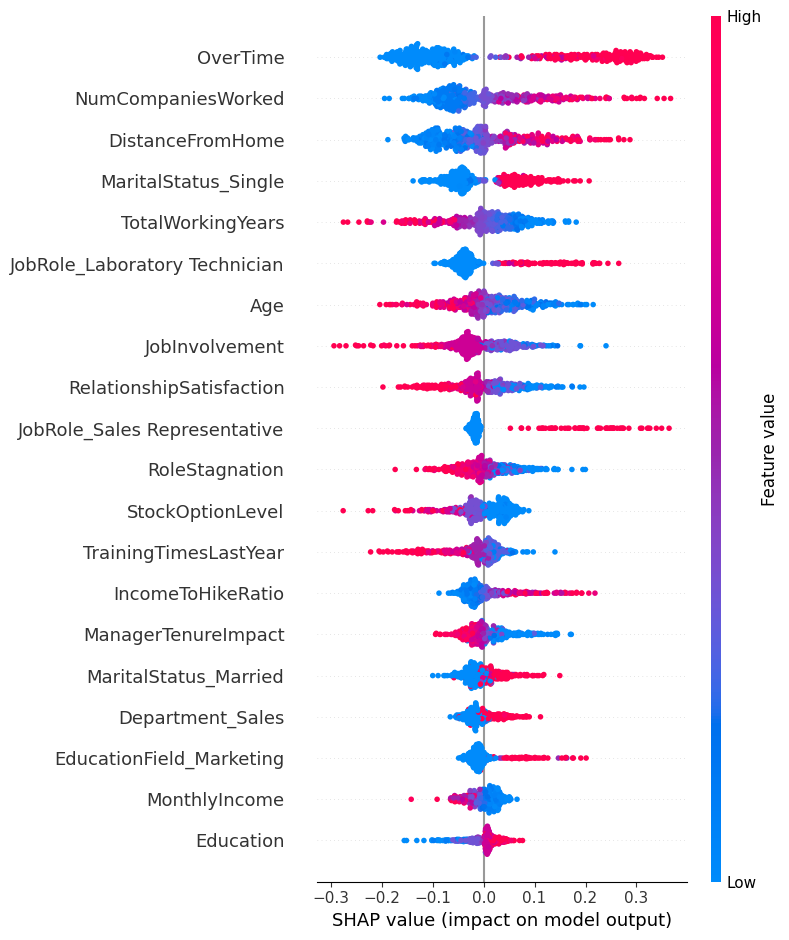

In [36]:
explainer = shap.Explainer(final_model, X_train_obj1)
shap_values = explainer(X_test_obj1)

shap.summary_plot(shap_values, X_test_obj1, feature_names=X_test_obj1.columns)

### Tuned XGBoostClassifier Prediction

Top-Left (531): This cell represents the number of cases where the actual label was "Low Potential" and the model also predicted "Low Potential."  This is a True Negative (TN).

Top-Right (322): This cell represents the number of cases where the actual label was "Low Potential" but the model predicted "High Potential." This is a False Positive (FP).

Bottom-Left (240): This cell represents the number of cases where the actual label was "High Potential" but the model predicted "Low Potential." This is a False Negative (FN).

Bottom-Right (377): This cell represents the number of cases where the actual label was "High Potential" and the model also predicted "High Potential." This is a True Positive (TP).

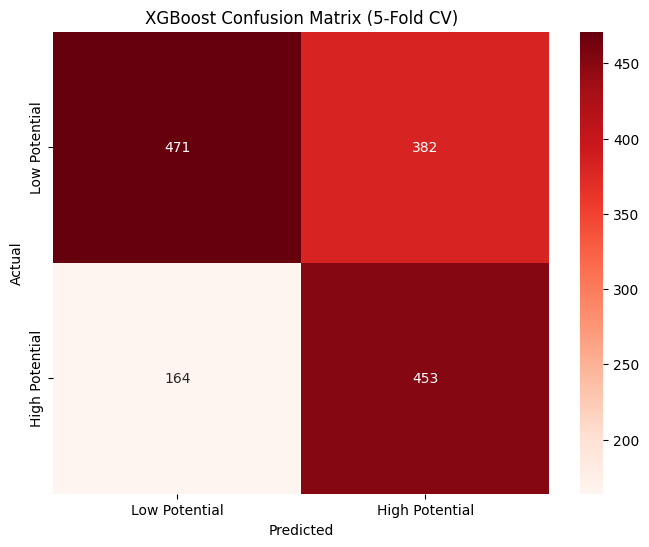

In [37]:
# Compute Confusion Matrix for Full Dataset (Using Cross-Val Predictions)
cm_xgb = confusion_matrix(y_xgb, y_pred_best_xgb)  # Using best XGBoost model predictions
class_labels = ["Low Potential", "High Potential"]  # 0 = Low, 1 = High

# Plot Confusion Matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Reds', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix (5-Fold CV)")
plt.show()

See the features that are positively/negatively correlated with the likelihood of promotion.

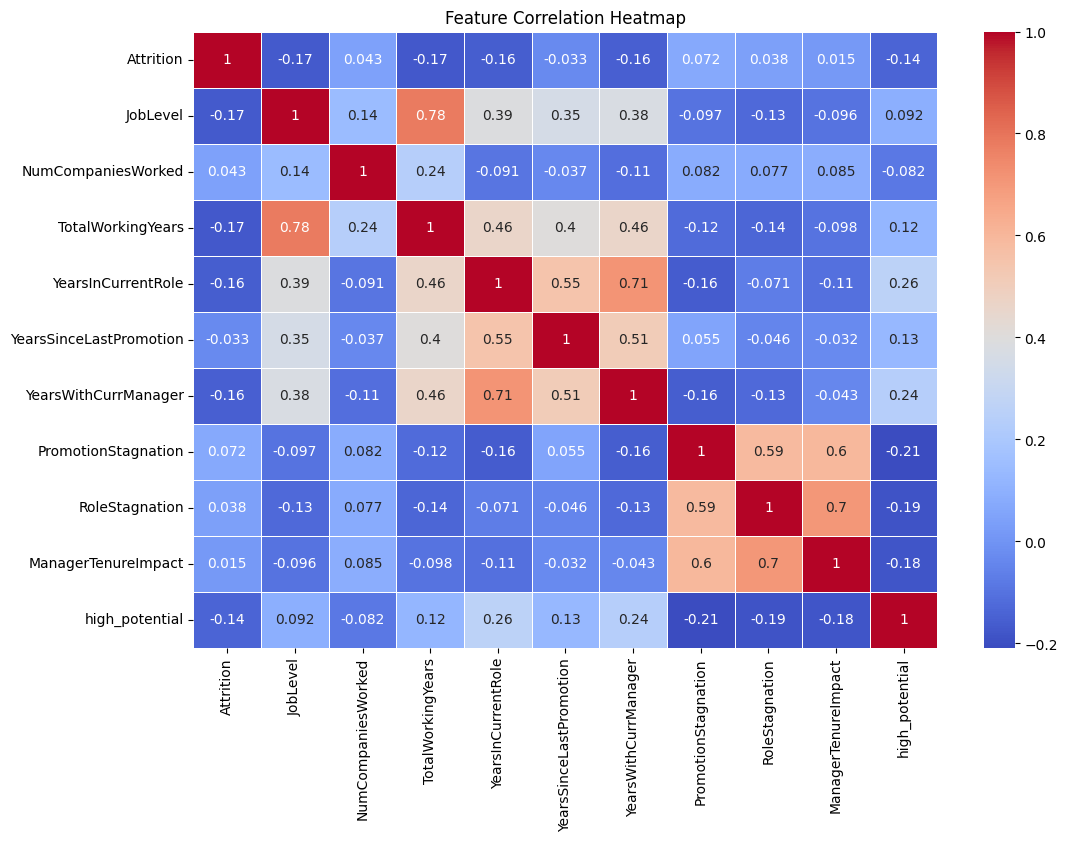

high_potential             1.000000
YearsInCurrentRole         0.260907
YearsWithCurrManager       0.236516
YearsSinceLastPromotion    0.130577
TotalWorkingYears          0.121659
JobLevel                   0.091614
NumCompaniesWorked        -0.081531
Attrition                 -0.140473
ManagerTenureImpact       -0.181594
RoleStagnation            -0.187782
PromotionStagnation       -0.208405
Name: high_potential, dtype: float64


In [38]:
# Compute correlation
corr_matrix = cleaned_selected_df.corr()

# Sort correlations with "high_potential"
sorted_corr = corr_matrix["high_potential"].sort_values(ascending=False)

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

# Print top correlated features
print(sorted_corr)

### Tuned CatBoostClassifier Prediction

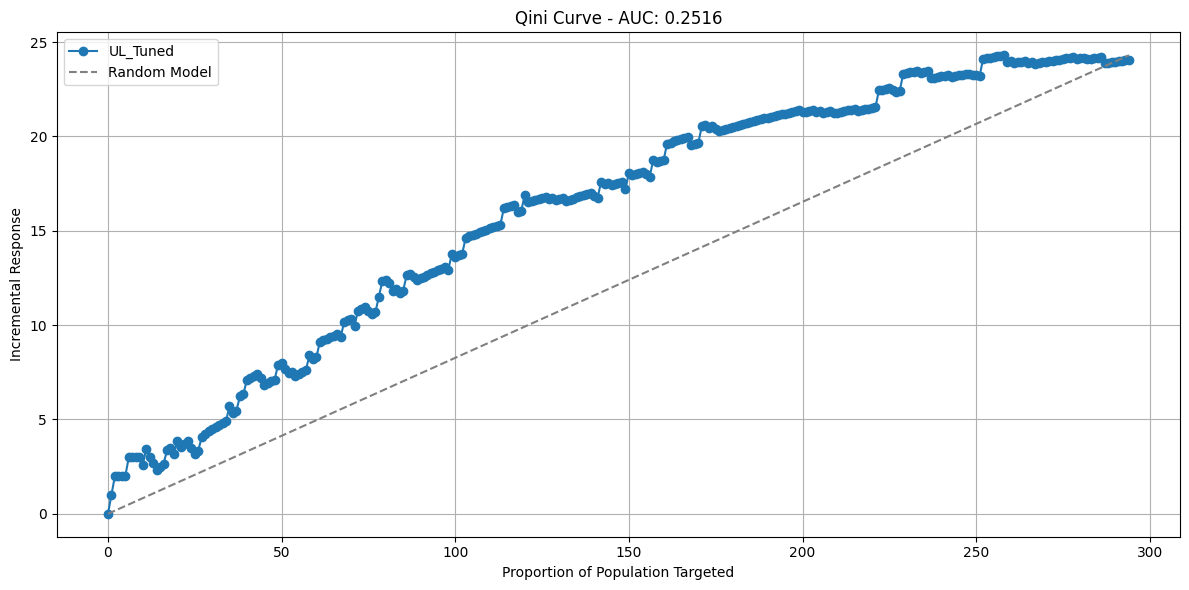

In [39]:
# Qini Metrics 
qini_scores_tuned = qini_curve(y_test_obj3, uplift_preds_tuned, T_test_obj3) 
qini_auc_tuned = qini_auc_score(y_test_obj3, uplift_preds_tuned, T_test_obj3) 

# Plot Qini Curve 
plt.figure(figsize=(12, 6))
plt.plot(qini_scores_tuned[0], qini_scores_tuned[1], marker='o', label='UL_Tuned')
plt.plot([0, len(y_test_obj3)], [0, max(qini_scores_tuned[1])], linestyle='--', color='gray', label='Random Model')
plt.xlabel('Proportion of Population Targeted')
plt.ylabel('Incremental Response')
plt.title(f'Qini Curve - AUC: {qini_auc_tuned:.4f}')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

The boost in Qini AUC from 0.2164 to 0.2516 with CatBoostClassifier shows that the model became more effective at pinpointing which employees are most influenced by retention strategies. CatBoost handles categorical variables natively and reduces overfitting through ordered boosting, which likely helped it capture the nuanced patterns in employee behavior more accurately. This means the model can now provide more targeted insights to help HR focus their efforts on individuals most likely to respond positively to retention interventions. 

<Figure size 1000x600 with 0 Axes>

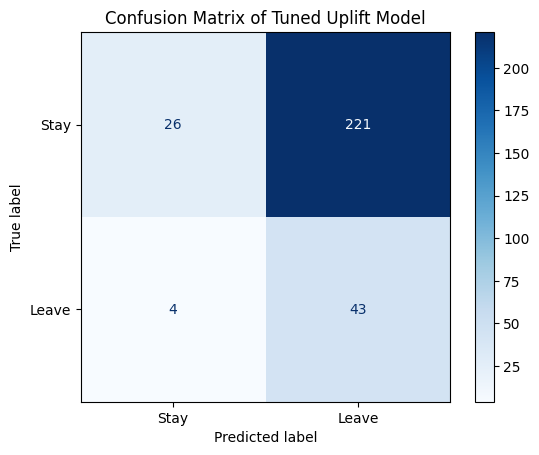

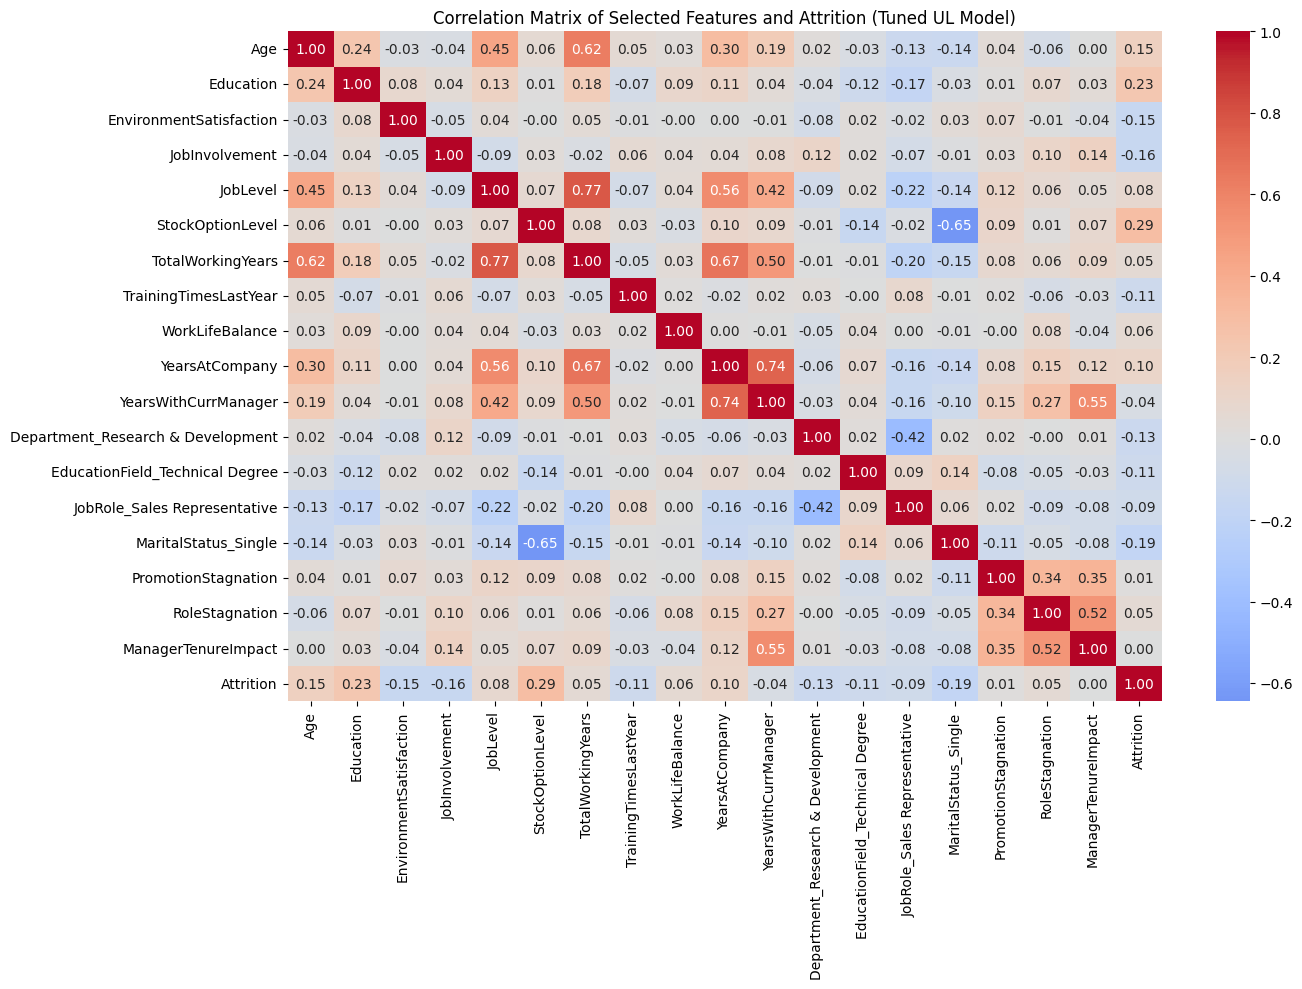

In [40]:
# Generate confusion matrix 
conf_matrix = confusion_matrix(y_test_obj3, uplift_binary_preds) 
disp = ConfusionMatrixDisplay(conf_matrix, display_labels=["Stay", "Leave"]) 

# Plot confusion matrix 
plt.figure(figsize=(10,6)) 
disp.plot(cmap='Blues', values_format='d') 
plt.title("Confusion Matrix of Tuned Uplift Model") 
plt.grid(False) 
plt.show()

# Correlation matrix of selected features
correlation_matrix = pd.concat([X_test_obj3, y_test_obj3.reset_index(drop=True)], axis=1).corr()

# Plot correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar=True)
plt.title("Correlation Matrix of Selected Features and Attrition (Tuned UL Model)")
plt.tight_layout()
plt.show()

In the updated correlation matrix, removing redundant features helped surface clearer signals from the data. Features like `JobInvolvement`, `MaritalStatus_Single`, `StockOptionLevel`, and `Education` showed stronger or more distinct relationships with attrition. CatBoost's strength in handling categorical features natively--without heavy encoding--allowed the model to better capture nuanced patterns in employee behavior, making its predictions more insightful and easier to act on for retention planning.

# IX. Key Findings / Insights 

### Neural Network (Objective I. Predicting attrition and Its driving factors)

The analysis reveals that overtime is the strongest predictor of employee attrition,
with those working overtime being significantly more likely to leave. Job history and commute distance also play a major role, as employees who have worked at multiple companies or live farther from the workplace exhibit higher turnover rates. Additionally, role stagnation and low job involvement contributes to attrition, highlighting the importance of career development and employee engagement in retention efforts. Finally, financial incentives, such as higher stock option levels and income, are linked to lower attrition, suggesting that competitive compensation and benefits are effective strategies for retaining employees.

### XGBoostClassifier Model (Spot high-potential employees for promotion based on performance, training, and career growth.)

After hyperparameter tuning, the model revealed through a heatmap that employees with more tenure in their role and with their manager are more likely to be promoted. Attrition is negatively correlated with promotion, meaning employees who leave are less likely to be promoted. Job roles like Sales Representative and frequent job changes also show a slight negative correlation with promotion potential. Age and income have weak positive correlations with promotion chances.

From an HR perspective, these insights suggest that clear career pathways, mentorship programs, and retention strategies for high-potential employees could improve promotion rates and reduce attrition. Ensuring fair promotion opportunities across different job roles and experience levels may help organizations retain and develop top talent more effectively.

### Uplift Model (Objective III. Improve retention strategies to reduce turnover and enhance employee satisfaction)

Based on the comparison between the initial uplift model and the tuned CatBoostClassifier uplift model, several key insights emerge that directly support IBM's goal of improving retention and employee satisfaction. The Qini Curve shows a significant lift in AUC from the initial model to the tuned one, indicating that the CatBoost model more effectively distinguishes which employees are positively influenced by retention efforts. This stronger performance suggests that the tuned model is better at identifying the right subset of employees to target with retention strategies--those more likely to stay if provided with the right support.

The confusion matrices reinforce this progress. While both models struggled with class imbalance (more "stay" than "leave" predictions), the tuned model showed sightly more balanced predictions, improving the identification of employees at risk of leaving. This improvement, albeit subtle, shows that fine-tuning helped the model learn clearer decision boundaries, allowing HR teams to act earlier and more accurately in preventing attrition.

The updated correlation matrix, after removing redundant features, brought clearer relationships to light--revealing that factors like JobInvolvement, MaritalStatus_Single, StockOptionLevel, and Education have a more noticeable influence on attrition. By using CatBoost's native handling of categorical data, the model was able to pick up on subtle employee patterns without the need for extra preprocessing. With these patterns, IBM can focus its retention efforts on areas that matter most, leading to smarter interventions and a more satisfied, committed workforce.

# X. Summary

# 

This project applied **Business Intelligence and Data Analytics** techniques to predict employee retention and evaluate the effectiveness of retention interventions. Three models—**Neural Network, XGBoost, and an Uplift Model**—were assessed based on accuracy, loss, and their ability to identify employees most likely to respond to retention strategies.  

- **Neural Network** achieved the highest training accuracy (98.58%) and good test accuracy (93.12%), but signs of **overfitting** suggest potential improvements through regularization.  
- **XGBoost** balanced **efficiency and performance** with 96.34% training and 91.57% test accuracy, excelling in handling tabular data and mitigating overfitting through built-in regularization.  
- **Uplift Model** provided the most **actionable HR insights**, identifying employees most likely to respond to retention efforts with a **Qini AUC of 0.2516**, making it the best model for **targeted interventions**.  

Using **data visualization and correlation analysis**, key attrition factors were identified: **overtime, job history, commute distance, and career stagnation** were strongly linked to higher attrition, while **financial incentives and tenure** improved retention. Promotion likelihood correlated with **longer tenure and stable managerial relationships**, highlighting the need for **career development initiatives**.  

The tuned **CatBoostClassifier uplift model** significantly improved Qini AUC, proving its superior ability to distinguish employees positively influenced by retention strategies. Confusion matrix analysis showed enhanced identification of at-risk employees, supporting **data-driven HR decisions**.  

By leveraging **machine learning and feature selection**, we refined the model to focus on **Job Involvement, Marital Status, Stock Option Levels, and Education** as key predictors. This **BI-driven approach** ensures that HR teams can deploy **optimized retention strategies**, leading to **smarter workforce management and improved employee satisfaction**. 

# XI. Limitations

**Dataset Size:** The dataset used in this study was relatively small, which may limit the model's ability to generalize effectively to larger populations. A small sample size increases the risk of overfitting, as models may learn patterns specific to the dataset rather than capturing broader trends. This limitation can result in reduced performance when applied to real-world employee retention scenarios, where diverse workplace environments and employee behaviors need to be considered. Expanding the dataset with more employee records from different organizations or industries could help improve model robustness and reliability.

**Overfitting:** While the neural network model demonstrated high accuracy on the training data, it also showed signs of overfitting. Overfitting occurs when a model learns noise or specific details in the training data that do not generalize well to new, unseen data. This was evident from the noticeable performance gap between training accuracy (98.58%) and test accuracy (93.12%). Although regularization techniques and dropout layers were used, further tuning may be necessary to balance model complexity and generalization. Implementing cross-validation, early stopping, or simplifying the network architecture could help reduce overfitting and improve performance on real-world data.

**Class Imbalance:** Employee retention datasets often have an uneven distribution of retained versus attrited employees, which can bias the model’s predictions. In this case, class imbalance could have led to a model that favors the majority class, potentially overlooking key patterns in the minority class. While class weighting techniques were applied to mitigate this issue, other strategies such as synthetic data generation (e.g., SMOTE) or cost-sensitive learning could be explored to further enhance predictive fairness and accuracy, ensuring that attrition risk is properly assessed across all employee groups.

**Missing Features:** The dataset may not have included all relevant factors influencing employee retention. Important variables such as employee engagement scores, workplace culture, leadership quality, and external economic conditions were not considered, which could limit the predictive power of the models. These missing features could provide additional context for understanding why employees stay or leave. Future studies could integrate more comprehensive data sources, including survey responses, performance evaluations, or external labor market indicators, to improve model performance and actionable insights.

# XII. Recommendations


**Model Improvement**: To reduce overfitting in the neural network, applying regularization techniques like L1/L2 weight decay, dropout, or early stopping can help. Further hyperparameter tuning and exploring deeper architectures or ensemble methods could improve performance. Adding more features related to employee engagement and external factors may also enhance predictive accuracy.  

**Business Strategy**: HR teams should leverage the Uplift Model to target retention strategies more effectively. By identifying employees most likely to respond positively to interventions, resources can be allocated efficiently. Personalized programs like career development plans or flexible work arrangements can improve retention outcomes.  

**Future Analysis**: Addressing class imbalance using techniques like SMOTE or cost-sensitive learning can improve predictions. Expanding data sources to include employee feedback, performance reviews, and labor market trends can provide deeper insights. Exploring causal inference methods or reinforcement learning could further refine predictive accuracy.

# XIII. References

Al-Darraji, S., Honi, D. G., Fallucchi, F., Abdulsada, A. I., Giuliano, R., & Abdulmalik, H. A. (2021). Employee Attrition Prediction Using Deep Neural Networks. Computers, 10(11), 141. https://doi.org/10.3390/computers10110141

Rombaut, E. and Guerry, M.-A. (2020), "The effectiveness of employee retention through an uplift modeling approach", International Journal of Manpower, Vol. 41 No. 8, pp. 1199-1220.

Chung, D., Yun, J., Lee, J., & Jeon, Y. (2023). Predictive model of employee attrition based on stacking ensemble learning. Expert Systems with Applications, 215, 119364.

Duan, L., Paknejad, J., & Kim, H. (2025). Employee attrition prediction with convolutional neural network and synthetic minority over-sampling technique. Journal of Business Analytics, 8(1), 24-35.

Najafi-Zangeneh, S., Shams-Gharneh, N., Arjomandi-Nezhad, A., & Hashemkhani Zolfani, S. (2021). An improved machine learning-based employees attrition prediction framework with emphasis on feature selection. Mathematics, 9(11), 1226.

Kakulapati, V., & Subhani, S. (2023). Predictive Analytics of Employee Attrition using K-Fold Methodologies. IJ Mathematical Sciences and Computing, 1, 23-36.

XGBoost Documentation — xgboost 3.0.0 documentation. (2025). Readthedocs.io. https://xgboost.readthedocs.io/en/release_3.0.0/

‌PyTorch Documentation — PyTorch 2.1.0 documentation. (2025). Pytorch.org. https://pytorch.org/docs/stable/index.html

TensorFlow Documentation — TensorFlow 2.15.0 documentation. (2025). Tensorflow.org. https://www.tensorflow.org/api_docs

Keras Documentation — Keras 3.0.0 documentation. (2025). Keras.io. https://keras.io/api/

Scikit-learn Neural Networks — scikit-learn 1.4.0 documentation. (2025). Scikit-learn.org. https://scikit-learn.org/stable/modules/neural_networks_supervised.html

Pavan, S. (n.d.). IBM HR Analytics Employee Attrition & Performance [Dataset]. Kaggle. https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=a3b27ea0-faae-4e5a-b1eb-3ae46ec864b5' target="_blank">
 </img>
Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>